# TUAB data preparation for LaBraM — from raw EDF to model input

This notebook walks through, step by step and on **real recordings**, how the
Temple University Hospital **Abnormal EEG Corpus (TUAB v3.0.0)** is turned into the
tensors LaBraM is fine-tuned on. Every step is (1) explained, (2) written as a
formula, and (3) visualised on a **normal** and an **abnormal** recording.

The code that does this in the repo is
[`dataset_maker/make_TUAB.py`](../dataset_maker/make_TUAB.py) (offline, EDF → pickle)
plus a few lines at training time in
[`labram/train/train_finetune.py`](../labram/train/train_finetune.py) (pickle → model input).
The notebook **re-implements the pipeline with the same MNE calls and the same constants
(imported from `make_TUAB.py`)** and checks at the end that it reproduces the stored
pickles exactly.

### The pipeline at a glance

| # | Step | Where | Shape after the step |
|---|------|-------|-----------------------|
| 0 | Read EDF, convert to µV | `mne.io.read_raw_edf` | `[C_raw ≈ 30–36, 250·T]` @ 250 Hz |
| 1 | Drop non-EEG channels, reorder to 23 standard channels | `raw.drop_channels`, `raw.reorder_channels` | `[23, 250·T]` |
| 2 | Band-pass FIR 0.1–75 Hz (zero phase) | `raw.filter(0.1, 75)` | `[23, 250·T]` |
| 3 | Notch FIR at 50 Hz | `raw.notch_filter(50)` | `[23, 250·T]` |
| 4 | Resample 250 → 200 Hz (FFT) | `raw.resample(200)` | `[23, 200·T]` |
| 5 | Cut into non-overlapping 10 s windows, label = folder | `X[:, 2000k : 2000(k+1)]` | `K × [23, 2000]` |
| 6 | *(training time)* scale ÷100, split into 1 s patches | `train_finetune.py` | `[23, 10, 200]` |
| 7 | *(optional, LaBraM++)* common average reference + per-patch z-score | `labram/data/preprocess.py` | `[23, 10, 200]` |

### Contents
1. The TUAB corpus: layout, labels, splits
2. Raw EDF signals (normal vs abnormal)
3. Step 1 — channel selection & ordering
4. Step 2 — band-pass filter 0.1–75 Hz
5. Step 3 — 50 Hz notch filter (and why 60 Hz survives)
6. Step 4 — resampling 250 → 200 Hz
7. Step 5 — windowing into 10 s samples, labels, verification against stored pickles
8. Step 6 — what the model actually receives (÷100, patches, channel indices)
9. Step 7 — optional LaBraM++ preprocessing (CAR + z-score)
10. Normal vs abnormal: gallery of examples & class-level spectra
11. Summary of formulas & caveats
12. Comparison with other state-of-the-art preprocessing pipelines (foundation models & brain-age models)

> **Requirements:** `mne`, `numpy`, `scipy`, `matplotlib`, `torch` (all in `requirements.txt`).
> Point `TUAB_ROOT` (below, or the `TUAB_ROOT` environment variable) to the `v3.0.0/edf`
> directory. The `processed/` sub-folder produced by `make_TUAB.py` is only needed for the
> verification and class-statistics sections; they are skipped if it is missing.

In [1]:
import os
import sys
import pickle
import collections
from pathlib import Path

import numpy as np
import scipy.signal as ss
import matplotlib.pyplot as plt
import mne

# --- paths -----------------------------------------------------------------
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))
sys.path.insert(0, str(REPO_ROOT / "dataset_maker"))

TUAB_ROOT = Path(os.environ.get(
    "TUAB_ROOT", "/data/datasets/EEG-public/TAUB/TUH_Abnormal/v3.0.0/edf"))
MONTAGE = "01_tcp_ar"                       # same as `channel_std` in make_TUAB.py
PROCESSED = TUAB_ROOT / "processed"         # output of make_TUAB.py (train/val/test)
assert TUAB_ROOT.exists(), f"TUAB_ROOT not found: {TUAB_ROOT}"

# --- the exact constants used by the preprocessing script --------------------
from make_TUAB import drop_channels, chOrder_standard   # noqa: E402

L_FREQ, H_FREQ = 0.1, 75.0     # raw.filter(l_freq=0.1, h_freq=75.0)
NOTCH_FREQ = 50.0              # raw.notch_filter(50.0)
TARGET_SFREQ = 200             # raw.resample(200)
WINDOW = 2000                  # 2000 samples = 10 s at 200 Hz
PATCH = 200                    # 1 s patches at training time

mne.set_log_level("ERROR")

# --- plotting style: one colour per class, used everywhere ---------------------
C_NORMAL, C_ABNORMAL = "#2a78d6", "#eb6834"
C_BEFORE, C_AFTER = "#9b9a95", "#2a78d6"
CLASS_COLOR = {0: C_NORMAL, 1: C_ABNORMAL}
CLASS_NAME = {0: "normal", 1: "abnormal"}
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False,
})
print("MNE", mne.__version__, "| TUAB root:", TUAB_ROOT)

MNE 1.4.2 | TUAB root: /data/datasets/EEG-public/TAUB/TUH_Abnormal/v3.0.0/edf


In [2]:
# ---------------------------------------------------------------------------
# Helpers used throughout the notebook
# ---------------------------------------------------------------------------
def short(ch):
    # 'EEG FP1-REF' -> 'FP1' (same rule as labram.data.eeg_constants.normalize_ch_names)
    return ch.split(" ")[-1].split("-")[0]


def plot_stacked(ax, X, ch_names, sfreq, t0=0.0, dur=10.0, spacing=None, color="k",
                 title=None, lw=0.6, clip=True, unit="µV", labels=None):
    # Stacked multichannel EEG trace. X in µV, shape [C, N].
    # Per-channel mean in the shown window is removed for display only.
    i0, i1 = int(round(t0 * sfreq)), int(round((t0 + dur) * sfreq))
    seg = X[:, i0:i1]
    seg = seg - seg.mean(axis=1, keepdims=True)
    if spacing is None:
        spacing = 4.0 * np.median(np.std(seg, axis=1))
        spacing = float(np.ceil(spacing / 10.0) * 10.0)
    t = t0 + np.arange(seg.shape[1]) / sfreq
    offsets = -np.arange(len(seg)) * spacing
    for k, (y, off) in enumerate(zip(seg, offsets)):
        if clip:
            y = np.clip(y, -1.5 * spacing, 1.5 * spacing)
        ax.plot(t, y + off, color=color, lw=lw)
    ax.set_yticks(offsets)
    ax.set_yticklabels(labels if labels is not None else [short(c) for c in ch_names], fontsize=7)
    ax.set_ylim(offsets[-1] - 1.5 * spacing, 1.5 * spacing)
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel("time [s]")
    ax.grid(False)
    if title:
        ax.set_title(f"{title}   (trace spacing = {spacing:g} {unit})")
    return spacing


def thick_legend(ax, **kw):
    # Legend whose line samples are thicker than the (thin) data lines
    leg = ax.legend(**kw)
    for line in leg.get_lines():
        line.set_linewidth(2.5)
    return leg


def welch_psd(X, sfreq, seg_sec=4.0):
    # Welch PSD per channel: X [C, N] in µV -> (f [Hz], P [C, F] in µV²/Hz).
    nper = int(seg_sec * sfreq)
    f, P = ss.welch(X, fs=sfreq, nperseg=nper, noverlap=nper // 2, axis=-1)
    return f, P


def line_ratio_db(f, P, f0, half=0.5):
    # Power at f0 relative to the neighbouring spectrum (f0±1..5 Hz), in dB.
    Pm = P.mean(axis=0) if P.ndim == 2 else P
    peak = Pm[(f >= f0 - half) & (f <= f0 + half)].max()
    nb = (np.abs(f - f0) > 1.0) & (np.abs(f - f0) < 5.0)
    return 10 * np.log10(peak / np.median(Pm[nb]))


def edf_path(split, label, stem):
    folder = "abnormal" if label == 1 else "normal"
    return TUAB_ROOT / split / folder / MONTAGE / f"{stem}.edf"


def run_pipeline(path, keep_stages=True):
    # Re-implements make_TUAB.split_and_dump step by step, keeping a copy (in µV) after
    # every step. Returns dict: stage name -> (X [C, N] µV, channel names, sfreq).
    stages = {}

    def snap(name):
        if keep_stages or name in ("0 raw", "4 resampled"):
            stages[name] = (raw.get_data(units="uV"), list(raw.ch_names), raw.info["sfreq"])

    raw = mne.io.read_raw_edf(path, preload=True)
    snap("0 raw")
    # step 1 — channel selection / ordering
    raw.drop_channels([ch for ch in drop_channels if ch in raw.ch_names])
    if len(chOrder_standard) == len(raw.ch_names):
        raw.reorder_channels(chOrder_standard)
    if raw.ch_names != chOrder_standard:
        raise RuntimeError(f"channel order is wrong for {path.name}: {raw.ch_names}")
    snap("1 channels")
    # step 2 — band-pass
    raw.filter(l_freq=L_FREQ, h_freq=H_FREQ)
    snap("2 band-pass")
    # step 3 — notch
    raw.notch_filter(NOTCH_FREQ)
    snap("3 notch")
    # step 4 — resample
    raw.resample(TARGET_SFREQ)
    snap("4 resampled")
    # step 5 — windows
    X = stages["4 resampled"][0]
    windows = np.stack([X[:, i * WINDOW:(i + 1) * WINDOW] for i in range(X.shape[1] // WINDOW)])
    return stages, windows

## 1. The TUAB corpus: layout, labels, splits

TUAB is a subset of the TUH EEG Corpus: routine clinical EEGs, each recording annotated by a
neurologist as **normal** or **abnormal** (based on the clinical report). The label is a
property of the **whole recording** — there is no time-resolved annotation.

```
v3.0.0/edf/
├── train/ ─┬─ normal/01_tcp_ar/aaaaaaav_s004_t000.edf
│           └─ abnormal/01_tcp_ar/...
└── eval/  ─┬─ normal/01_tcp_ar/...
            └─ abnormal/01_tcp_ar/...
```

* File name = `<subject>_<session>_<token>.edf` — e.g. `aaaaaaav_s004_t000` is subject
  `aaaaaaav`, session 4, the first EDF file of that session.
* **Label** comes only from the folder name: $y = 1$ for `abnormal/`, $y = 0$ for `normal/`.
* `01_tcp_ar` = recordings made with an *averaged reference* (AR) electrode configuration;
  every channel is a referential channel named `EEG XX-REF`.

**How `make_TUAB.py` splits the data** (subject-level, done separately for each class $c$):

$$
\mathcal S^{c}_{\text{train/val}} = \text{shuffle}\big(\{\text{subject ids in } \texttt{train}/c\}\big),\qquad
\mathcal S^{c}_{\text{train}} = \mathcal S^{c}_{[\,0 : \lfloor 0.8\,|\mathcal S^{c}|\rfloor\,)},\quad
\mathcal S^{c}_{\text{val}} = \mathcal S^{c}_{[\,\lfloor 0.8\,|\mathcal S^{c}|\rfloor : \,]}
$$

and the official `eval/` folder becomes the **test** set. (Caveats about this split are in
section 11.)

split  class      y  #recordings  #subjects
train  normal     0         1371       1237
train  abnormal   1         1346        893
eval   normal     0          150        148
eval   abnormal   1          126        105


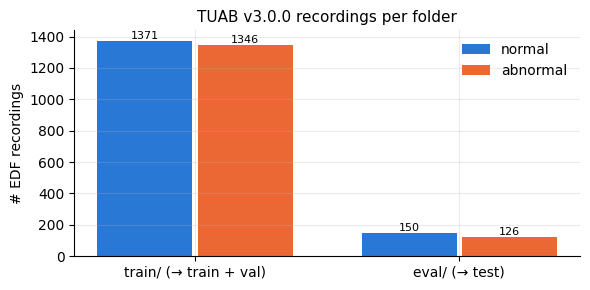

In [3]:
rows = []
for split in ["train", "eval"]:
    for label, folder in [(0, "normal"), (1, "abnormal")]:
        files = sorted(p.name for p in (TUAB_ROOT / split / folder / MONTAGE).glob("*.edf"))
        subjects = {f.split("_")[0] for f in files}
        rows.append((split, folder, label, len(files), len(subjects)))

print(f"{'split':6s} {'class':9s} {'y':>2s} {'#recordings':>12s} {'#subjects':>10s}")
for r in rows:
    print(f"{r[0]:6s} {r[1]:9s} {r[2]:>2d} {r[3]:>12d} {r[4]:>10d}")

fig, ax = plt.subplots(figsize=(6, 3))
x = np.arange(2)
for j, (label, name) in enumerate([(0, "normal"), (1, "abnormal")]):
    vals = [r[3] for r in rows if r[2] == label]
    bars = ax.bar(x + (j - 0.5) * 0.38, vals, width=0.36, color=CLASS_COLOR[label], label=name)
    ax.bar_label(bars, fontsize=8)
ax.set_xticks(x, ["train/ (→ train + val)", "eval/ (→ test)"])
ax.set_ylabel("# EDF recordings")
ax.set_title("TUAB v3.0.0 recordings per folder")
ax.legend()
plt.tight_layout()
plt.show()

### Pick the examples used in the walk-through

We use recordings from the `eval/` (= test) folder, taken in sorted order so the choice is
deterministic. Change `EXAMPLE_NORMAL` / `EXAMPLE_ABNORMAL` to look at other recordings.
`SHOW_T0` is the start (in seconds) of the 10 s excerpt that is plotted — the first minute of
a clinical EEG often contains set-up artefacts, so we look a bit later.

In [4]:
eval_normal = sorted(p.stem for p in (TUAB_ROOT / "eval/normal" / MONTAGE).glob("*.edf"))
eval_abnormal = sorted(p.stem for p in (TUAB_ROOT / "eval/abnormal" / MONTAGE).glob("*.edf"))

EXAMPLE_NORMAL = eval_normal[0]
EXAMPLE_ABNORMAL = eval_abnormal[0]
SHOW_T0, SHOW_DUR = 120.0, 10.0

examples = {0: EXAMPLE_NORMAL, 1: EXAMPLE_ABNORMAL}
pipe = {}
for label, stem in examples.items():
    pipe[label] = run_pipeline(edf_path("eval", label, stem))
    print(f"{CLASS_NAME[label]:9s} {stem}: processed into {len(pipe[label][1])} windows")

normal    aaaaaayx_s002_t000: processed into 120 windows


abnormal  aaaaabdo_s003_t000: processed into 121 windows


## 2. Raw EDF signals

An EDF file stores each channel as 16-bit integers $d[n]$ together with a calibration
(physical/digital min/max) in the header. MNE converts them to volts, and `get_data(units="uV")`
converts to microvolts:

$$
x_{\text{V}}[n] = p_{\min} + \big(d[n] - d_{\min}\big)\,\frac{p_{\max} - p_{\min}}{d_{\max} - d_{\min}},
\qquad x_{\mu\text{V}}[n] = 10^{6}\, x_{\text{V}}[n].
$$

What the raw recordings look like:
* sampling rate $f_s = 250$ Hz (anti-aliasing low-pass of the amplifier: 125 Hz),
* 30–36 channels — the 23 scalp/ear EEG electrodes **plus** non-EEG channels (EKG, EMG,
  eye leads `ROC/LOC`, photic stimulator, `IBI/BURSTS/SUPPR` analysis channels, unused
  numbered inputs `EEG 26-REF`, …),
* DC offsets and slow drifts, and power-line interference.

In [5]:
for label, stem in examples.items():
    X, ch, sf = pipe[label][0]["0 raw"]
    print(f"--- {CLASS_NAME[label]}: {stem} ---")
    print(f"sfreq = {sf:.0f} Hz | duration = {X.shape[1] / sf:.0f} s | {len(ch)} channels | shape {X.shape}")
    print("channels:", ", ".join(ch))
    print()

--- normal: aaaaaayx_s002_t000 ---
sfreq = 250 Hz | duration = 1202 s | 36 channels | shape (36, 300500)
channels: EEG FP1-REF, EEG FP2-REF, EEG F3-REF, EEG F4-REF, EEG C3-REF, EEG C4-REF, EEG P3-REF, EEG P4-REF, EEG O1-REF, EEG O2-REF, EEG F7-REF, EEG F8-REF, EEG T3-REF, EEG T4-REF, EEG T5-REF, EEG T6-REF, EEG A1-REF, EEG A2-REF, EEG FZ-REF, EEG CZ-REF, EEG PZ-REF, EEG ROC-REF, EEG LOC-REF, EEG EKG1-REF, EMG-REF, EEG 26-REF, EEG 27-REF, EEG 28-REF, EEG 29-REF, EEG 30-REF, EEG T1-REF, EEG T2-REF, PHOTIC-REF, IBI, BURSTS, SUPPR

--- abnormal: aaaaabdo_s003_t000 ---
sfreq = 250 Hz | duration = 1217 s | 30 channels | shape (30, 304250)
channels: EEG FP1-REF, EEG FP2-REF, EEG F3-REF, EEG F4-REF, EEG C3-REF, EEG C4-REF, EEG P3-REF, EEG P4-REF, EEG O1-REF, EEG O2-REF, EEG F7-REF, EEG F8-REF, EEG T3-REF, EEG T4-REF, EEG T5-REF, EEG T6-REF, EEG A1-REF, EEG A2-REF, EEG FZ-REF, EEG CZ-REF, EEG PZ-REF, EEG ROC-REF, EEG LOC-REF, EEG EKG1-REF, EEG T1-REF, EEG T2-REF, PHOTIC-REF, IBI, BURSTS, SUPPR


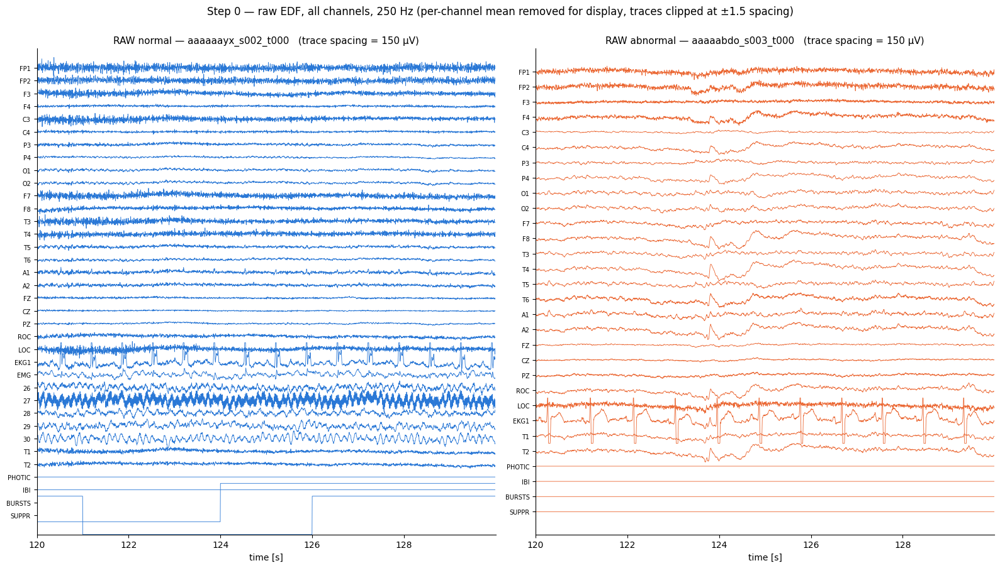

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X, ch, sf = pipe[label][0]["0 raw"]
    plot_stacked(ax, X, ch, sf, SHOW_T0, SHOW_DUR, color=CLASS_COLOR[label], spacing=150,
                 title=f"RAW {CLASS_NAME[label]} — {stem}")
fig.suptitle("Step 0 — raw EDF, all channels, 250 Hz (per-channel mean removed for display, "
             "traces clipped at ±1.5 spacing)", y=1.0)
plt.tight_layout()
plt.show()

The spectrum of the raw signal (Welch PSD, 4 s Hann segments, averaged over the 23 EEG
channels) shows the three things the next steps deal with: a lot of power near 0 Hz
(drift / DC), content all the way to the 125 Hz amplifier cut-off, and — in many recordings, here
very clearly in the abnormal one — a sharp spectral line at **60 Hz** (US power mains).

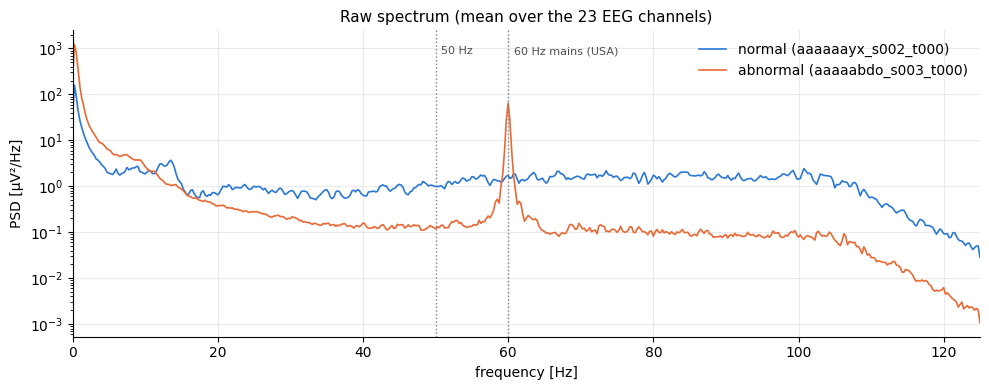

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for label, stem in examples.items():
    X, ch, sf = pipe[label][0]["0 raw"]
    eeg = [ch.index(c) for c in chOrder_standard]
    f, P = welch_psd(X[eeg], sf)
    ax.semilogy(f, P.mean(0), color=CLASS_COLOR[label], lw=1.2, label=f"{CLASS_NAME[label]} ({stem})")
for f0, txt in [(50, "50 Hz"), (60, "60 Hz mains (USA)")]:
    ax.axvline(f0, color="0.5", ls=":", lw=1)
    ax.text(f0 + 0.8, ax.get_ylim()[1] * 0.3, txt, fontsize=8, color="0.3")
ax.set_xlim(0, 125)
ax.set_xlabel("frequency [Hz]")
ax.set_ylabel("PSD [µV²/Hz]")
ax.set_title("Raw spectrum (mean over the 23 EEG channels)")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Step 1 — channel selection & ordering

`make_TUAB.py` defines a list $\mathcal D$ of channels to drop (`drop_channels`: EKG, EMG,
ROC/LOC, PHOTIC, IBI/BURSTS/SUPPR, RESP, `EEG 20-REF … EEG 128-REF`, …) and a fixed target
order $\mathcal O$ of 23 channels (`chOrder_standard`):

$$
\mathcal C_{\text{keep}} = \mathcal C_{\text{raw}} \setminus \mathcal D, \qquad
\text{require } |\mathcal C_{\text{keep}}| = 23, \qquad
X^{(1)}[i,\,:] = X^{(0)}[\pi(i),\,:]\ \ \text{with } \pi(i) = \text{index of } \mathcal O_i \text{ in } \mathcal C_{\text{raw}}.
$$

If after dropping the file does not contain exactly these 23 channels, the recording is
**skipped** and its name written to `tuab-process-error-files.txt`.

The 23 channels are the 19 electrodes of the international 10-20 system
(Fp1, Fp2, F3, F4, C3, C4, P3, P4, O1, O2, F7, F8, T3, T4, T5, T6, Fz, Cz, Pz), the two ear
electrodes **A1/A2** and the anterior temporal electrodes **T1/T2**. Later, LaBraM maps each name
to its index in the 62-channel `standard_1020` list for the spatial position embedding
(section 8).

normal    aaaaaayx_s002_t000: 36 raw -> drop 13 -> keep 23
   dropped: EEG ROC-REF, EEG LOC-REF, EEG EKG1-REF, EMG-REF, EEG 26-REF, EEG 27-REF, EEG 28-REF, EEG 29-REF, EEG 30-REF, PHOTIC-REF, IBI, BURSTS, SUPPR
abnormal  aaaaabdo_s003_t000: 30 raw -> drop 7 -> keep 23
   dropped: EEG ROC-REF, EEG LOC-REF, EEG EKG1-REF, PHOTIC-REF, IBI, BURSTS, SUPPR

target order (23): FP1, FP2, F3, F4, C3, C4, P3, P4, O1, O2, F7, F8, T3, T4, T5, T6, A1, A2, FZ, CZ, PZ, T1, T2



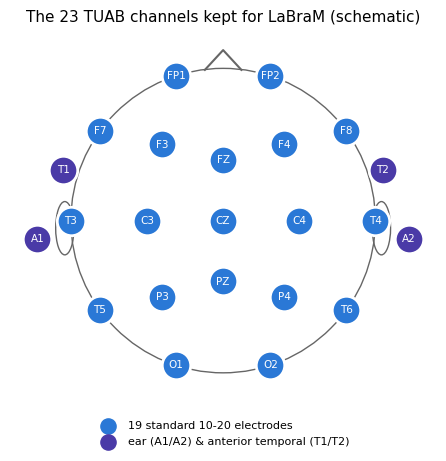

In [8]:
for label, stem in examples.items():
    _, ch_raw, _ = pipe[label][0]["0 raw"]
    dropped = [c for c in ch_raw if c in drop_channels]
    kept = [c for c in ch_raw if c not in drop_channels]
    print(f"{CLASS_NAME[label]:9s} {stem}: {len(ch_raw)} raw -> drop {len(dropped)} -> keep {len(kept)}")
    print("   dropped:", ", ".join(dropped))
print()
print("target order (23):", ", ".join(short(c) for c in chOrder_standard))
print()

# Electrode layout of the 23 channels (schematic 2-D 10-20 projection, nose up).
# A1/A2 sit on the ear lobes and T1/T2 below the 10-20 plane, so they are drawn
# outside / at the rim of the head circle.
POS2D = {
    "FP1": (-0.31, 0.95), "FP2": (0.31, 0.95), "F7": (-0.81, 0.59), "F3": (-0.40, 0.50),
    "FZ": (0.0, 0.40), "F4": (0.40, 0.50), "F8": (0.81, 0.59), "T3": (-1.0, 0.0),
    "C3": (-0.50, 0.0), "CZ": (0.0, 0.0), "C4": (0.50, 0.0), "T4": (1.0, 0.0),
    "T5": (-0.81, -0.59), "P3": (-0.40, -0.50), "PZ": (0.0, -0.40), "P4": (0.40, -0.50),
    "T6": (0.81, -0.59), "O1": (-0.31, -0.95), "O2": (0.31, -0.95),
    "A1": (-1.22, -0.12), "A2": (1.22, -0.12), "T1": (-1.05, 0.33), "T2": (1.05, 0.33),
}
EXTRA = {"A1", "A2", "T1", "T2"}
C_EXTRA = "#4a3aa7"
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.add_patch(plt.Circle((0, 0), 1.0, fill=False, color="0.4"))
ax.plot([-0.12, 0, 0.12], [0.99, 1.12, 0.99], color="0.4")                       # nose
for side in (-1, 1):
    ax.add_patch(plt.matplotlib.patches.Ellipse((side * 1.04, -0.05), 0.12, 0.35, fill=False, color="0.4"))
for name in (short(c) for c in chOrder_standard):
    x_, y_ = POS2D[name]
    ax.scatter(x_, y_, s=420, color=C_EXTRA if name in EXTRA else C_NORMAL, edgecolor="white", lw=2, zorder=3)
    ax.text(x_, y_, name, ha="center", va="center", fontsize=7.5, color="white", zorder=4)
ax.scatter([], [], s=120, color=C_NORMAL, label="19 standard 10-20 electrodes")
ax.scatter([], [], s=120, color=C_EXTRA, label="ear (A1/A2) & anterior temporal (T1/T2)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.25, 1.25)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("The 23 TUAB channels kept for LaBraM (schematic)")
plt.show()

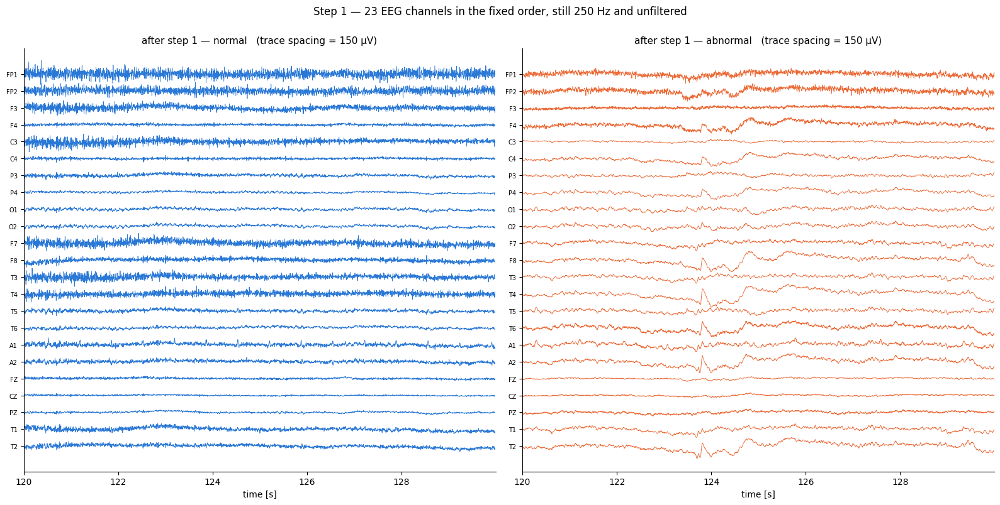

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X, ch, sf = pipe[label][0]["1 channels"]
    plot_stacked(ax, X, ch, sf, SHOW_T0, SHOW_DUR, color=CLASS_COLOR[label], spacing=150,
                 title=f"after step 1 — {CLASS_NAME[label]}")
fig.suptitle("Step 1 — 23 EEG channels in the fixed order, still 250 Hz and unfiltered", y=1.0)
plt.tight_layout()
plt.show()

## 4. Step 2 — band-pass filter 0.1–75 Hz

`raw.filter(l_freq=0.1, h_freq=75.0)` uses MNE's defaults: a **linear-phase FIR** filter
designed with the **window method** (`firwin`, Hamming window) and applied with
**zero phase** (delay-compensated, non-causal).

**Design.** An ideal band-pass between $f_1$ and $f_2$ has impulse response
(difference of two ideal low-passes, $\operatorname{sinc}(u) = \sin(\pi u)/(\pi u)$):

$$
h_d[n] = \frac{2 f_2}{f_s}\operatorname{sinc}\!\Big(\frac{2 f_2 n}{f_s}\Big) - \frac{2 f_1}{f_s}\operatorname{sinc}\!\Big(\frac{2 f_1 n}{f_s}\Big).
$$

It is truncated to $N$ taps and multiplied by a Hamming window
$w[n] = 0.54 - 0.46\cos\!\big(\tfrac{2\pi n}{N-1}\big)$:
$\;h[n] = h_d\!\big[n - \tfrac{N-1}{2}\big]\, w[n],\ n = 0..N-1.$
The cut-offs $f_1, f_2$ are placed in the middle of the transition bands
(the −6 dB points). MNE's automatic transition bandwidths are

$$
\Delta f_{l} = \min\!\big(\max(0.25\,f_l,\ 2),\ f_l\big) = 0.1\ \text{Hz},\qquad
\Delta f_{h} = \min\!\big(\max(0.25\,f_h,\ 2),\ \tfrac{f_s}{2} - f_h\big) = 18.75\ \text{Hz},
$$

so the −6 dB cut-offs are at $0.1 - 0.05 = 0.05$ Hz and $75 + 9.375 = 84.4$ Hz, and the filter
length for a Hamming window is

$$
N = \Big\lceil 3.3\,\frac{f_s}{\min(\Delta f_l, \Delta f_h)} \Big\rceil\ (\text{odd}) = 8251 \text{ taps} \approx 33\ \text{s}.
$$

(The very long filter is the price of the very narrow 0.1 Hz transition at the low end.)

**Application (zero phase).** Since $h$ is symmetric, centring it removes the
$(N-1)/2$-sample delay:

$$
y[n] = \sum_{k=0}^{N-1} h[k]\; x\!\Big[n + \tfrac{N-1}{2} - k\Big],
$$

with the signal padded at both ends by reflection (`pad="reflect_limited"`) to reduce edge effects.

**Why.** Below 0.1 Hz there is no useful brain signal in a clinical EEG — only electrode
offset, sweat and movement drift. Above ~75 Hz the scalp EEG is dominated by muscle (EMG)
and instrument noise; 75 Hz also keeps the signal well below the 100 Hz Nyquist frequency of
the 200 Hz target rate (step 4).

band-pass FIR: 8251 taps = 33.0 s, Hamming window, zero phase


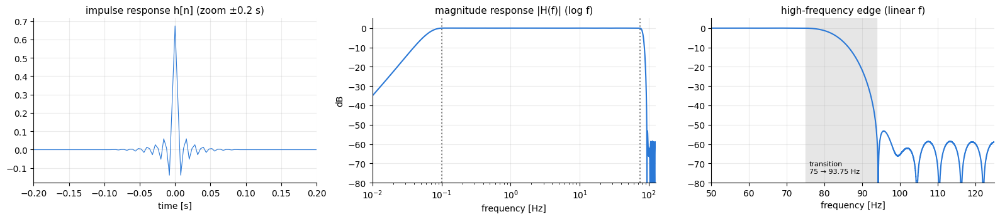

In [10]:
sf0 = 250.0
h_bp = mne.filter.create_filter(None, sf0, L_FREQ, H_FREQ)          # identical design to raw.filter
w, H = ss.freqz(h_bp, worN=2 ** 18, fs=sf0)
print(f"band-pass FIR: {len(h_bp)} taps = {len(h_bp) / sf0:.1f} s, Hamming window, zero phase")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
t_h = (np.arange(len(h_bp)) - (len(h_bp) - 1) / 2) / sf0
axes[0].plot(t_h, h_bp, color=C_AFTER, lw=0.8)
axes[0].set_xlim(-0.2, 0.2)
axes[0].set_title("impulse response h[n] (zoom ±0.2 s)")
axes[0].set_xlabel("time [s]")
axes[1].semilogx(w[1:], 20 * np.log10(np.abs(H[1:]) + 1e-12), color=C_AFTER)
axes[1].set_xlim(0.01, 125)
axes[1].set_ylim(-80, 5)
for fc in (L_FREQ, H_FREQ):
    axes[1].axvline(fc, color="0.5", ls=":")
axes[1].set_title("magnitude response |H(f)| (log f)")
axes[1].set_xlabel("frequency [Hz]")
axes[1].set_ylabel("dB")
axes[2].plot(w, 20 * np.log10(np.abs(H) + 1e-12), color=C_AFTER)
axes[2].set_xlim(50, 125)
axes[2].set_ylim(-80, 5)
axes[2].axvspan(75, 93.75, color="0.9", zorder=0)
axes[2].text(76, -75, "transition\n75 → 93.75 Hz", fontsize=8)
axes[2].set_title("high-frequency edge (linear f)")
axes[2].set_xlabel("frequency [Hz]")
plt.tight_layout()
plt.show()

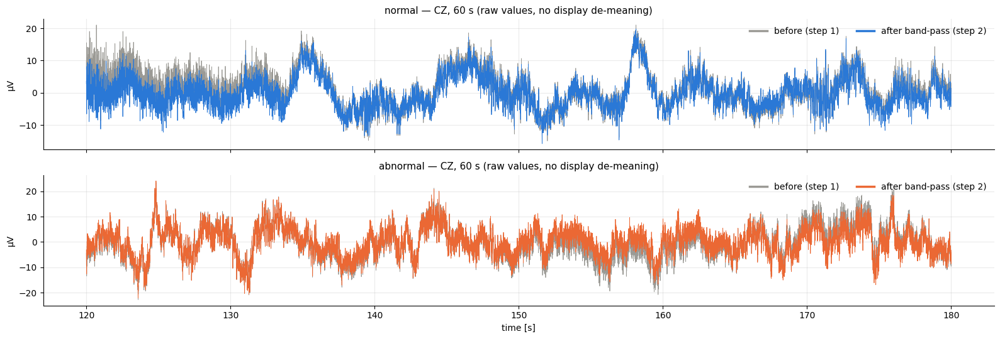

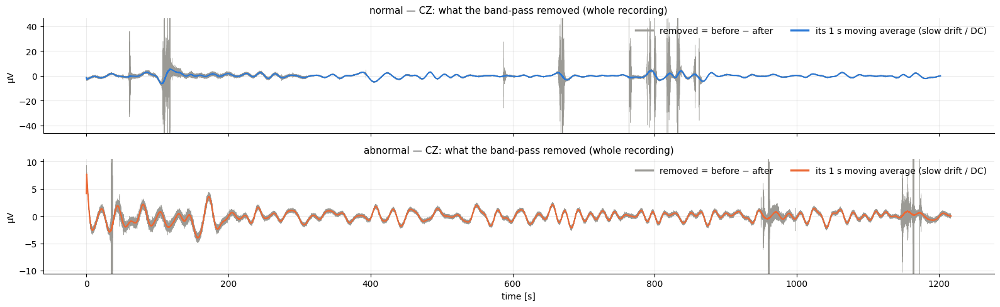

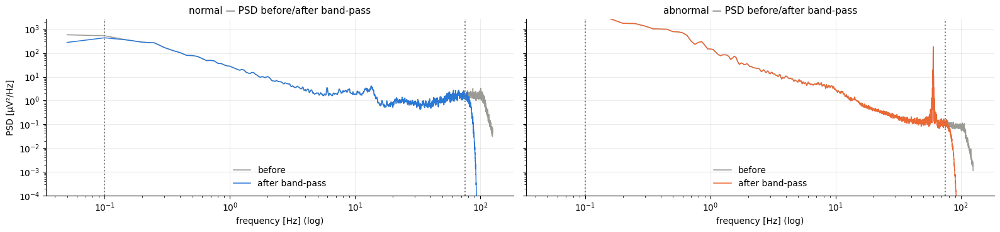

In [11]:
# One channel, 60 s: the slow drift is removed, the waveform is preserved.
CH = "EEG CZ-REF"
fig, axes = plt.subplots(2, 1, figsize=(16, 5.5), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X1, ch, sf = pipe[label][0]["1 channels"]
    X2, _, _ = pipe[label][0]["2 band-pass"]
    i = ch.index(CH)
    i0, i1 = int(SHOW_T0 * sf), int((SHOW_T0 + 60) * sf)
    t = np.arange(i0, i1) / sf
    ax.plot(t, X1[i, i0:i1], color=C_BEFORE, lw=0.6, label="before (step 1)")
    ax.plot(t, X2[i, i0:i1], color=CLASS_COLOR[label], lw=0.6, label="after band-pass (step 2)")
    ax.set_ylabel("µV")
    ax.set_title(f"{CLASS_NAME[label]} — {short(CH)}, 60 s (raw values, no display de-meaning)")
    thick_legend(ax, loc="upper right", ncol=2)
axes[-1].set_xlabel("time [s]")
plt.tight_layout()
plt.show()

# What exactly did the filter take out?  removed = before − after, over the whole recording.
# Its 1 s moving average is the slow drift (< 0.1 Hz) — the rest is > 75 Hz noise.
fig, axes = plt.subplots(2, 1, figsize=(16, 5), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X1, ch, sf = pipe[label][0]["1 channels"]
    X2, _, _ = pipe[label][0]["2 band-pass"]
    i = ch.index(CH)
    removed = X1[i] - X2[i]
    slow = np.convolve(removed, np.ones(int(sf)) / sf, mode="same")
    t = np.arange(len(removed)) / sf
    ax.plot(t, removed, color=C_BEFORE, lw=0.3, label="removed = before − after")
    ax.plot(t, slow, color=CLASS_COLOR[label], lw=1.5, label="its 1 s moving average (slow drift / DC)")
    lim = np.percentile(np.abs(removed), 99.9) * 1.3
    ax.set_ylim(-lim, lim)
    ax.set_ylabel("µV")
    ax.set_title(f"{CLASS_NAME[label]} — {short(CH)}: what the band-pass removed (whole recording)")
    thick_legend(ax, loc="upper right", ncol=2)
axes[-1].set_xlabel("time [s]")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), sharey=True)
for ax, (label, stem) in zip(axes, examples.items()):
    for st, col, nm in [("1 channels", C_BEFORE, "before"), ("2 band-pass", CLASS_COLOR[label], "after band-pass")]:
        X, ch, sf = pipe[label][0][st]
        f, P = welch_psd(X, sf, seg_sec=20.0)
        ax.loglog(f[1:], P.mean(0)[1:], color=col, lw=1.1, label=nm)
    for fc in (L_FREQ, H_FREQ):
        ax.axvline(fc, color="0.5", ls=":")
    ax.set_ylim(1e-4, None)
    ax.set_title(f"{CLASS_NAME[label]} — PSD before/after band-pass")
    ax.set_xlabel("frequency [Hz] (log)")
    ax.legend()
axes[0].set_ylabel("PSD [µV²/Hz]")
plt.tight_layout()
plt.show()

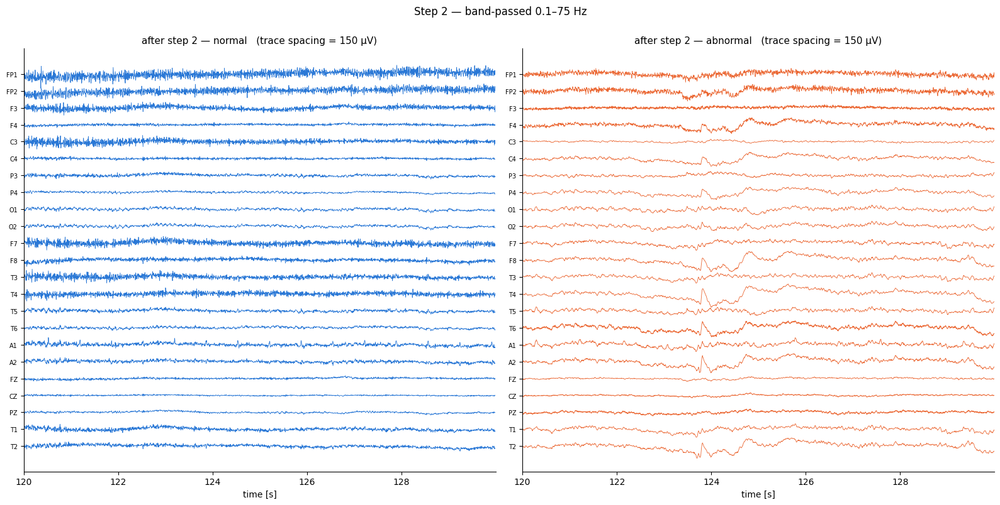

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X, ch, sf = pipe[label][0]["2 band-pass"]
    plot_stacked(ax, X, ch, sf, SHOW_T0, SHOW_DUR, color=CLASS_COLOR[label], spacing=150,
                 title=f"after step 2 — {CLASS_NAME[label]}")
fig.suptitle("Step 2 — band-passed 0.1–75 Hz", y=1.0)
plt.tight_layout()
plt.show()

## 5. Step 3 — 50 Hz notch filter

`raw.notch_filter(50.0)` builds a narrow FIR **band-stop** filter (same window method, Hamming,
zero phase). With the defaults `notch_widths = f_0/200 = 0.25` Hz and `trans_bandwidth = 1` Hz:

$$
h_{\text{notch}}[n] = \delta[n] - h_{\text{bp}}^{[f_0 - w/2,\ f_0 + w/2]}[n],\qquad
|H_{\text{notch}}(f)| \approx
\begin{cases}
0 & |f - f_0| \le w/2 \\
1 & |f - f_0| \ge w/2 + \Delta f
\end{cases}
$$

i.e. it removes a sliver of spectrum $50 \pm 0.125$ Hz and leaves everything outside
$\approx 49.4$–$50.6$ Hz untouched.

> ⚠️ **TUH EEG was recorded in the USA, where the mains frequency is 60 Hz, not 50 Hz.**
> The 50 Hz notch therefore does essentially nothing on TUAB, and because the band-pass keeps
> everything up to 75 Hz, the **60 Hz line noise stays in the training data**. The numbers and
> plots below quantify this. (The script was written for a mix of datasets; it is kept as-is
> here because the published checkpoints were trained on data processed exactly this way —
> changing it would change the input distribution.)

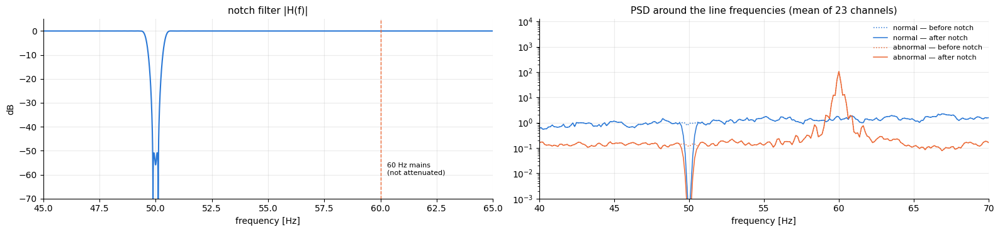

recording                     50 Hz before  50 Hz after  60 Hz before  60 Hz after  (peak / neighbourhood, dB)


normal aaaaaayx_s002_t000             -0.3         -1.7           1.3          1.3


abnormal aaaaabdo_s003_t000            0.0         -1.7          26.9         26.9


In [13]:
# Frequency response of the notch: pass a unit impulse through the very same function
imp = np.zeros(2 ** 16)
imp[len(imp) // 2] = 1.0
h_notch = mne.filter.notch_filter(imp[np.newaxis], sf0, NOTCH_FREQ)[0]
Hn = np.fft.rfft(h_notch)
fn = np.fft.rfftfreq(len(h_notch), 1 / sf0)

fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
axes[0].plot(fn, 20 * np.log10(np.abs(Hn) + 1e-12), color=C_AFTER)
axes[0].set_xlim(45, 65)
axes[0].set_ylim(-70, 5)
axes[0].axvline(60, color=C_ABNORMAL, ls="--", lw=1)
axes[0].text(60.3, -60, "60 Hz mains\n(not attenuated)", fontsize=8)
axes[0].set_title("notch filter |H(f)|")
axes[0].set_xlabel("frequency [Hz]")
axes[0].set_ylabel("dB")

for label, stem in examples.items():
    for st, ls_ in [("2 band-pass", ":"), ("3 notch", "-")]:
        X, ch, sf = pipe[label][0][st]
        f, P = welch_psd(X, sf, seg_sec=8.0)
        axes[1].semilogy(f, P.mean(0), color=CLASS_COLOR[label], ls=ls_, lw=1.1,
                         label=f"{CLASS_NAME[label]} — {'before' if st[0] == '2' else 'after'} notch")
axes[1].set_xlim(40, 70)
axes[1].set_ylim(1e-3, None)
axes[1].set_title("PSD around the line frequencies (mean of 23 channels)")
axes[1].set_xlabel("frequency [Hz]")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'recording':28s} {'50 Hz before':>13s} {'50 Hz after':>12s} {'60 Hz before':>13s} {'60 Hz after':>12s}  (peak / neighbourhood, dB)")
for label, stem in examples.items():
    vals = []
    for f0 in (50, 60):
        for st in ("2 band-pass", "3 notch"):
            X, ch, sf = pipe[label][0][st]
            f, P = welch_psd(X, sf, seg_sec=8.0)
            vals.append(line_ratio_db(f, P, f0))
    print(f"{CLASS_NAME[label] + ' ' + stem:28s} {vals[0]:13.1f} {vals[1]:12.1f} {vals[2]:13.1f} {vals[3]:12.1f}")

## 6. Step 4 — resampling 250 → 200 Hz

LaBraM works with **200 samples per second** (one patch = 200 samples = 1 s) for all datasets.
`raw.resample(200)` uses MNE's **FFT (Fourier) method** with a boxcar window: the signal of
length $N$ is transformed, its spectrum is truncated to the new Nyquist band, and transformed
back with the new length $N' = \operatorname{round}(N \cdot 200 / 250) = 0.8\,N$:

$$
X[k] = \sum_{n=0}^{N-1} x[n]\, e^{-j 2\pi k n / N},\qquad
x'[m] = \frac{N'}{N}\cdot\frac{1}{N'} \sum_{|k| < N'/2} X[k]\, e^{\,j 2\pi k m / N'},\quad m = 0..N'-1 .
$$

(The signal is first padded — `npad="auto"` to a fast FFT length, edges by reflection.)
Truncating the spectrum at the new Nyquist frequency $f_s'/2 = 100$ Hz is an ideal
anti-aliasing low-pass. Because step 2 already removed everything above ~85 Hz
(≥ 53 dB attenuation from 93.75 Hz), nothing is aliased and the spectrum below 75 Hz is unchanged.

normal   : 300500 samples @ 250 Hz -> 240400 samples @ 200 Hz (ratio 0.8000)


abnormal : 304250 samples @ 250 Hz -> 243400 samples @ 200 Hz (ratio 0.8000)


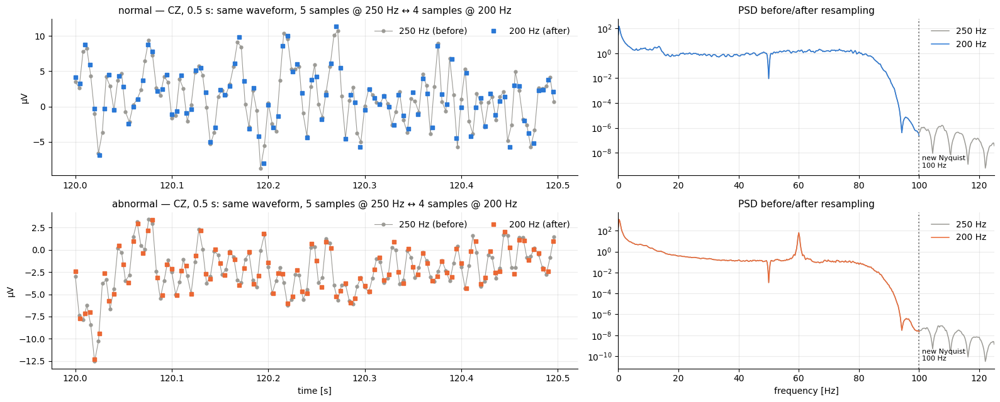

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.4, 1]})
for row, (label, stem) in enumerate(examples.items()):
    X3, ch, sf3 = pipe[label][0]["3 notch"]
    X4, _, sf4 = pipe[label][0]["4 resampled"]
    i = ch.index(CH)
    t_a, t_b = SHOW_T0, SHOW_T0 + 0.5
    m3 = (np.arange(X3.shape[1]) / sf3 >= t_a) & (np.arange(X3.shape[1]) / sf3 < t_b)
    m4 = (np.arange(X4.shape[1]) / sf4 >= t_a) & (np.arange(X4.shape[1]) / sf4 < t_b)
    ax = axes[row, 0]
    ax.plot(np.arange(X3.shape[1])[m3] / sf3, X3[i, m3], "o-", ms=3.5, lw=0.8, color=C_BEFORE, label="250 Hz (before)")
    ax.plot(np.arange(X4.shape[1])[m4] / sf4, X4[i, m4], "s", ms=4, color=CLASS_COLOR[label], label="200 Hz (after)")
    ax.set_title(f"{CLASS_NAME[label]} — {short(CH)}, 0.5 s: same waveform, 5 samples @ 250 Hz ↔ 4 samples @ 200 Hz")
    ax.set_ylabel("µV")
    ax.legend(loc="upper right", ncol=2)
    ax = axes[row, 1]
    for X, sf, col, nm in [(X3, sf3, C_BEFORE, "250 Hz"), (X4, sf4, CLASS_COLOR[label], "200 Hz")]:
        f, P = welch_psd(X, sf, seg_sec=4.0)
        ax.semilogy(f, P.mean(0), color=col, lw=1.1, label=nm)
    ax.axvline(100, color="0.5", ls=":")
    ax.text(101, 0.05, "new Nyquist\n100 Hz", fontsize=8, transform=ax.get_xaxis_transform())
    ax.set_xlim(0, 125)
    ax.set_title("PSD before/after resampling")
    ax.legend()
    print(f"{CLASS_NAME[label]:9s}: {X3.shape[1]} samples @ {sf3:.0f} Hz -> {X4.shape[1]} samples @ {sf4:.0f} Hz "
          f"(ratio {X4.shape[1] / X3.shape[1]:.4f})")
axes[1, 0].set_xlabel("time [s]")
axes[1, 1].set_xlabel("frequency [Hz]")
plt.tight_layout()
plt.show()

## 7. Step 5 — windowing into 10 s samples, labels, verification

After resampling, the recording $X \in \mathbb R^{23 \times N'}$ (µV, 200 Hz) is cut into
**non-overlapping** windows of $W = 2000$ samples (10 s):

$$
K = \Big\lfloor \frac{N'}{W} \Big\rfloor,\qquad
X_k = X[:,\ kW : (k+1)W] \in \mathbb R^{23\times 2000},\quad k = 0..K-1,
$$

and the last $N' \bmod W$ samples (< 10 s) are discarded. Every window inherits the label of
its recording, $y_k = y$, and is saved as

```python
pickle.dump({"X": X_k, "y": y}, open(f"processed/<split>/<stem>_<k>.pkl", "wb"))
```

There is **no** artefact rejection, re-referencing or amplitude normalisation in this offline
step — windows containing movement or electrode artefacts (the large bursts in the plot below,
clipped by the y-axis) are kept as they are.

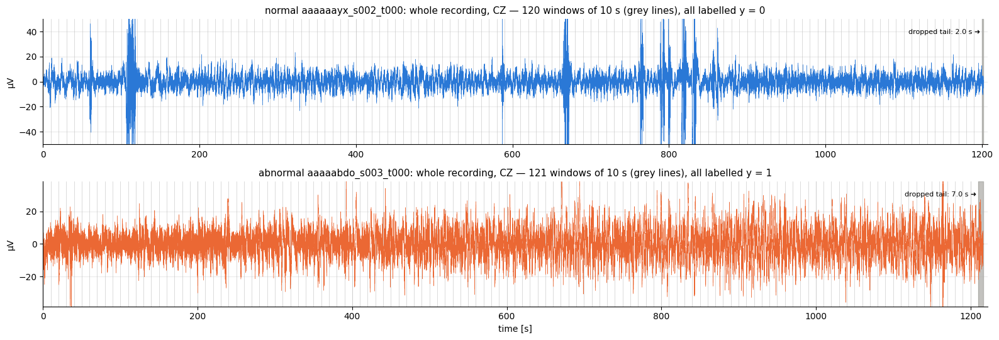

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(16, 5.5), sharey=False)
for ax, (label, stem) in zip(axes, examples.items()):
    X, ch, sf = pipe[label][0]["4 resampled"]
    i = ch.index(CH)
    K = X.shape[1] // WINDOW
    t = np.arange(X.shape[1]) / sf
    ax.plot(t, X[i], color=CLASS_COLOR[label], lw=0.3)
    for k in range(K + 1):
        ax.axvline(k * WINDOW / sf, color="0.75", lw=0.4, zorder=0)
    ax.axvspan(K * WINDOW / sf, t[-1], color=C_BEFORE, alpha=0.6)
    ax.text(K * WINDOW / sf - 2, 0.92, f"dropped tail: {(X.shape[1] - K * WINDOW) / sf:.1f} s ➜",
            fontsize=8, ha="right", va="top", transform=ax.get_xaxis_transform())
    lim = np.percentile(np.abs(X[i]), 99.5) * 1.5
    ax.set_ylim(-lim, lim)
    ax.set_xlim(0, t[-1] + 5)
    ax.set_ylabel("µV")
    ax.set_title(f"{CLASS_NAME[label]} {stem}: whole recording, {short(CH)} — {K} windows of 10 s (grey lines), all labelled y = {label}")
axes[-1].set_xlabel("time [s]")
plt.tight_layout()
plt.show()

### Verification: does this notebook reproduce the stored pickles?

`make_TUAB.py` puts each recording in exactly one of `processed/{train,val,test}`. We look the
example recordings up there and compare every window.

In [16]:
def find_processed(stem):
    for split in ("train", "val", "test"):
        if (PROCESSED / split / f"{stem}_0.pkl").exists():
            return split
    return None

if PROCESSED.exists():
    for label, stem in examples.items():
        split = find_processed(stem)
        if split is None:
            print(f"{stem}: not found in {PROCESSED} (recording was skipped by make_TUAB.py?)")
            continue
        windows = pipe[label][1]
        diffs, labels = [], set()
        for k in range(len(windows)):
            with open(PROCESSED / split / f"{stem}_{k}.pkl", "rb") as fh:
                s = pickle.load(fh)
            diffs.append(np.abs(s["X"] - windows[k]).max())
            labels.add(int(s["y"]))
        extra = (PROCESSED / split / f"{stem}_{len(windows)}.pkl").exists()
        print(f"{CLASS_NAME[label]:9s} {stem} [{split}]: {len(windows)} windows, "
              f"max |stored − notebook| = {max(diffs):.2e} µV, stored y = {labels}, extra windows on disk: {extra}")
else:
    print("processed/ folder not found — skipping verification")

normal    aaaaaayx_s002_t000 [test]: 120 windows, max |stored − notebook| = 3.41e-13 µV, stored y = {0}, extra windows on disk: False


abnormal  aaaaabdo_s003_t000 [test]: 121 windows, max |stored − notebook| = 1.82e-12 µV, stored y = {1}, extra windows on disk: False


## 8. Step 6 — what the model actually receives

At training/evaluation time the `TUABLoader` reads a pickle and returns
`(torch.FloatTensor(X), y)` (it would resample to another rate only if `sampling_rate ≠ 200`).
Then `train_finetune.py` does two more things:

```python
samples = samples.float() / 100                                    # µV -> units of 100 µV
samples = rearrange(samples, 'B N (A T) -> B N A T', T=200)        # 1 s patches
```

$$
\tilde x_{c,a,t} = \frac{X_{c,\;200a + t}}{100},\qquad c = 1..23,\ \ a = 0..9 \ (\text{patch}),\ \ t = 0..199 .
$$

* **Scaling by 1/100** brings typical EEG amplitudes (tens of µV) to $O(0.1$–$1)$ — a fixed,
  global scale (no per-sample normalisation), identical to pre-training.
* **Patching**: each channel's 10 s window becomes 10 patches of 1 s → 23 × 10 = 230 tokens.
  Each patch is embedded by the temporal convolution; LaBraM adds a **temporal embedding**
  (patch index $a$) and a **spatial embedding** chosen by the electrode's index in the 62-channel
  `standard_1020` list (`get_channel_indices`, index 0 is the CLS token).

channel names  : ['FP1', 'FP2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'A1', 'A2', 'FZ', 'CZ', 'PZ', 'T1', 'T2']
input_chans    : [0, 1, 3, 18, 22, 40, 44, 62, 66, 81, 83, 16, 24, 89, 91, 90, 92, 95, 96, 20, 42, 64, 113, 114] (0 = CLS token, others = 1 + index in standard_1020)

one window (23, 2000) µV  ->  model input (1, 23, 10, 200) (B, channels, patches, samples)
value range after /100: min -1.17, max 0.88, std 0.208


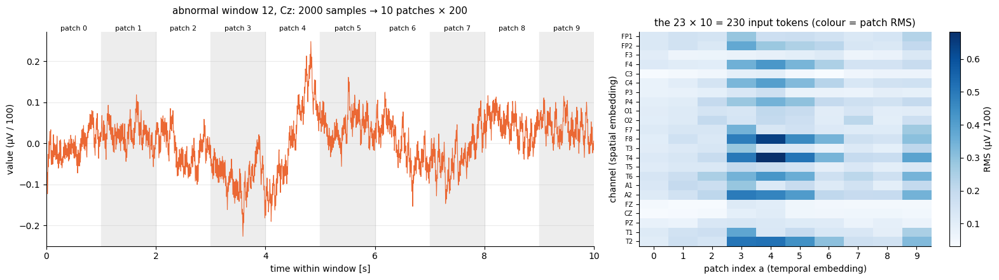

In [17]:
import torch
from einops import rearrange
from labram.data.eeg_constants import get_channel_indices, normalize_ch_names, TUH_EEG_CH_NAMES

ch_names = normalize_ch_names(TUH_EEG_CH_NAMES)
print("channel names  :", ch_names)
print("input_chans    :", get_channel_indices(ch_names), "(0 = CLS token, others = 1 + index in standard_1020)")
assert ch_names == [short(c) for c in chOrder_standard]

label = 1
windows = pipe[label][1]
k_show = int(SHOW_T0 // 10)                       # the window containing the excerpt shown above
x = torch.FloatTensor(windows[k_show])[None] / 100
xp = rearrange(x, "B N (A T) -> B N A T", T=PATCH)
print(f"\none window {tuple(windows[k_show].shape)} µV  ->  model input {tuple(xp.shape)} (B, channels, patches, samples)")
print(f"value range after /100: min {xp.min():.2f}, max {xp.max():.2f}, std {xp.std():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
sig = x[0, ch_names.index("CZ")].numpy()
ax.plot(np.arange(len(sig)) / TARGET_SFREQ, sig, color=CLASS_COLOR[label], lw=0.8)
for a in range(10):
    if a % 2:
        ax.axvspan(a, a + 1, color="0.93", zorder=0)
    ax.text(a + 0.5, 1.0, f"patch {a}", ha="center", va="bottom", fontsize=8,
            transform=ax.get_xaxis_transform())
ax.set_xlim(0, 10)
ax.set_xlabel("time within window [s]")
ax.set_ylabel("value (µV / 100)")
ax.set_title(f"{CLASS_NAME[label]} window {k_show}, Cz: 2000 samples → 10 patches × 200", pad=20)
ax = axes[1]
rms = xp[0].pow(2).mean(-1).sqrt().numpy()
im = ax.imshow(rms, aspect="auto", cmap="Blues")
ax.set_yticks(range(23), ch_names, fontsize=7)
ax.set_xticks(range(10))
ax.set_xlabel("patch index a (temporal embedding)")
ax.set_ylabel("channel (spatial embedding)")
ax.grid(False)
ax.set_title("the 23 × 10 = 230 input tokens (colour = patch RMS)")
plt.colorbar(im, ax=ax, label="RMS (µV / 100)")
plt.tight_layout()
plt.show()

## 9. Step 7 (optional) — LaBraM++ preprocessing: CAR + per-patch z-score

Off by default. With `labram_plus.enabled=true` (see `docs/labram_plus_plus.md`) the model
itself applies two more transforms to every patch tensor $x \in \mathbb R^{B\times N\times A\times T}$
(`labram/data/preprocess.py`), first CAR then z-scoring:

**Common average reference** — subtract the instantaneous mean over the $N$ electrodes:

$$
x^{\text{CAR}}_{b,c,a,t} = x_{b,c,a,t} - \frac{1}{N}\sum_{c'=1}^{N} x_{b,c',a,t}.
$$

**Per-patch z-score** — standardise each (channel, patch) over its 200 samples
($\sigma$ is the unbiased standard deviation, $\varepsilon = 10^{-5}$):

$$
z_{b,c,a,t} = \frac{x^{\text{CAR}}_{b,c,a,t} - \mu_{b,c,a}}{\sigma_{b,c,a} + \varepsilon},\qquad
\mu_{b,c,a} = \frac{1}{T}\sum_t x^{\text{CAR}}_{b,c,a,t}.
$$

Note the z-score removes per-patch amplitude information entirely (every patch has unit
variance) — it equalises channels but hides "this patch is larger than usual".

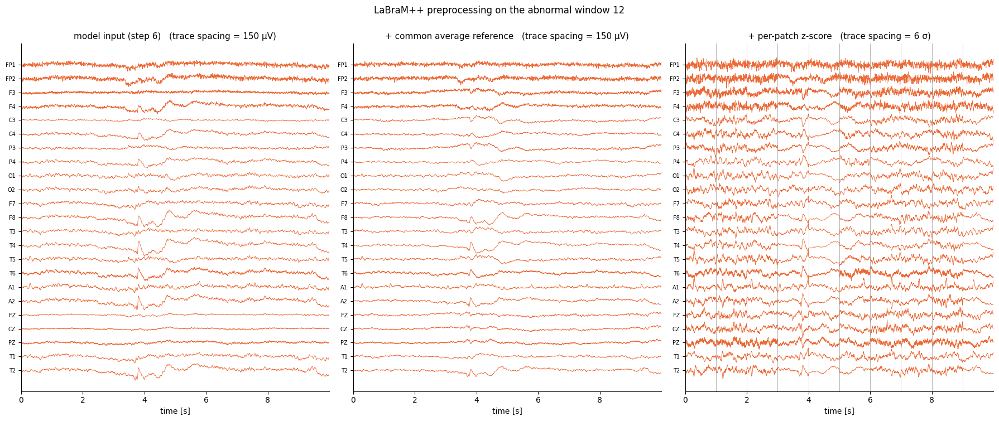

In [18]:
from labram.data.preprocess import common_average_reference, z_score_per_patch

x_car = common_average_reference(xp)
x_z = z_score_per_patch(x_car)

def flat(t):
    return rearrange(t, "B N A T -> B N (A T)")[0].numpy() * 100   # back to µV-like units for display

fig, axes = plt.subplots(1, 3, figsize=(18, 7.5), sharex=True)
plot_stacked(axes[0], flat(xp), chOrder_standard, TARGET_SFREQ, 0, 10, spacing=150, color=C_ABNORMAL,
             title="model input (step 6)")
plot_stacked(axes[1], flat(x_car), chOrder_standard, TARGET_SFREQ, 0, 10, spacing=150, color=C_ABNORMAL,
             title="+ common average reference")
plot_stacked(axes[2], flat(x_z) / 100, chOrder_standard, TARGET_SFREQ, 0, 10, spacing=6, color=C_ABNORMAL,
             title="+ per-patch z-score", unit="σ")
for a in range(1, 10):
    axes[2].axvline(a, color="0.6", lw=0.5)
fig.suptitle(f"LaBraM++ preprocessing on the {CLASS_NAME[label]} window {k_show}", y=1.0)
plt.tight_layout()
plt.show()

## 10. Normal vs abnormal: examples and class-level spectra

### Gallery

Three normal and three abnormal recordings from the test set. For each we show the **raw**
signal (step 0, 23 EEG channels only, 250 Hz) next to the **final 10 s window** that is stored on
disk (after step 5).

Which window to show? Showing the first window is biased toward set-up artefacts, and picking
the cleanest one would be cherry-picking. We show a **typical window**: the one whose 99th-percentile
absolute amplitude is the median over all windows of that recording.

What to look for (clinical heuristics, not a rule — many abnormal EEGs look normal in any
given 10 s): normal adult EEG typically has a clear **posterior alpha rhythm (8–13 Hz)** at
O1/O2/P3/P4 during relaxed wakefulness; abnormal recordings more often show **slowing**
(excess delta 0.5–4 Hz / theta 4–8 Hz), focal or asymmetric activity, or epileptiform
discharges (spikes / sharp waves).

Note that raw and processed windows look **very similar** at this scale: the pipeline removes
drift, > 75 Hz content and resamples — it does not "clean" the EEG of artefacts or change the
morphology of the brain activity a neurologist would look at.

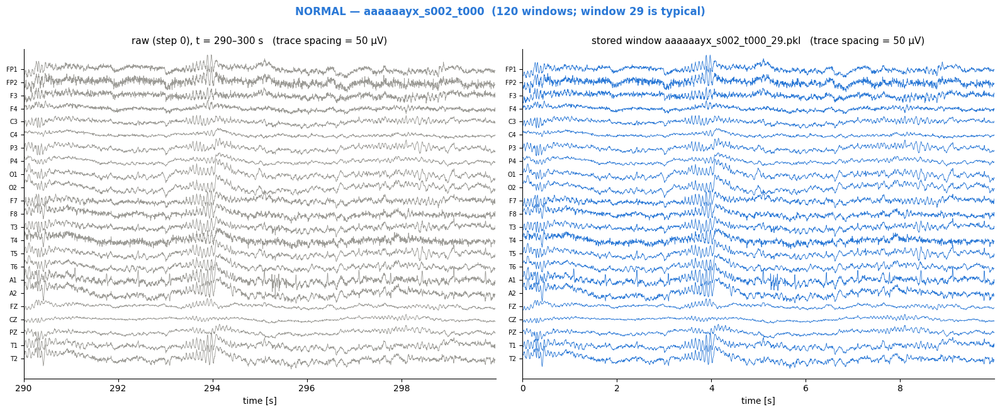

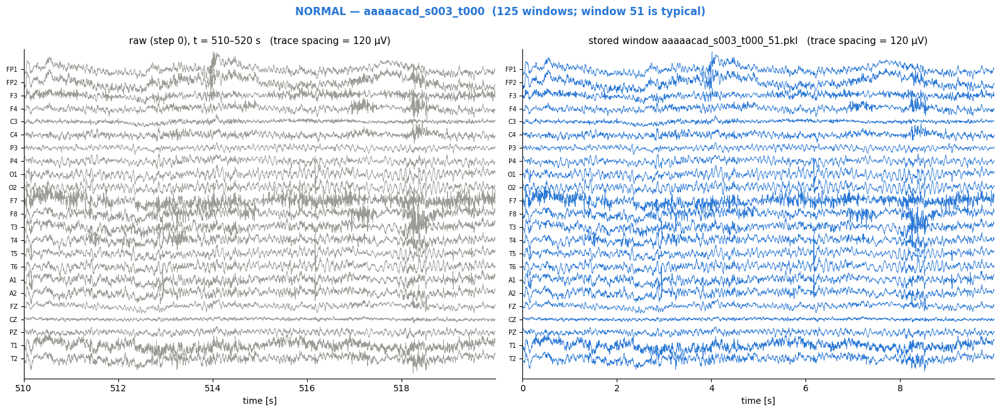

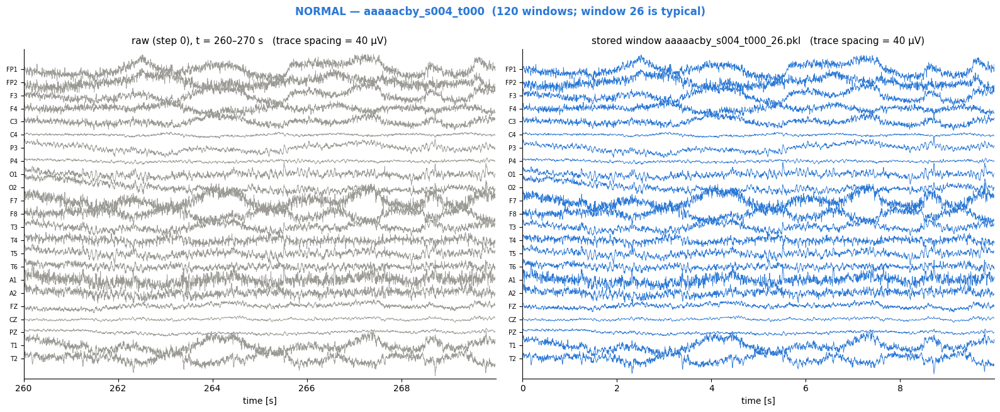

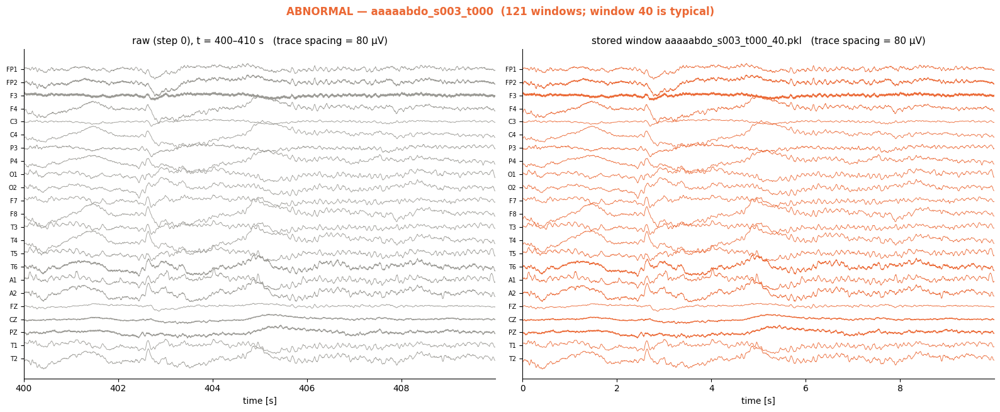

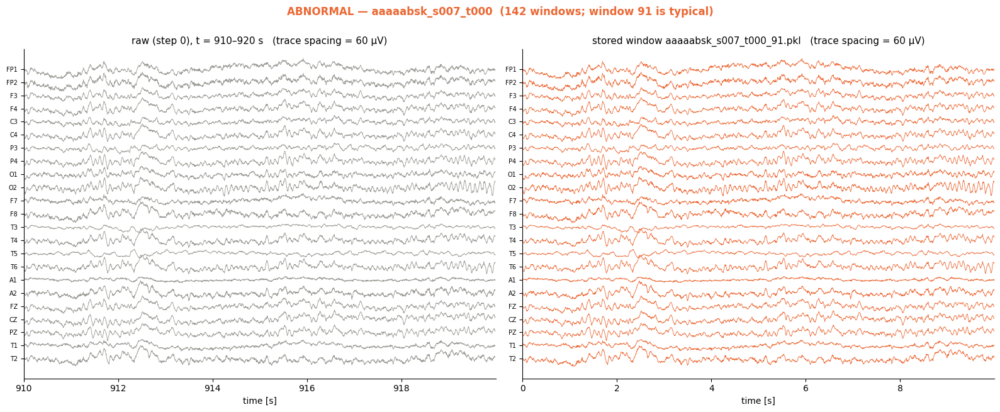

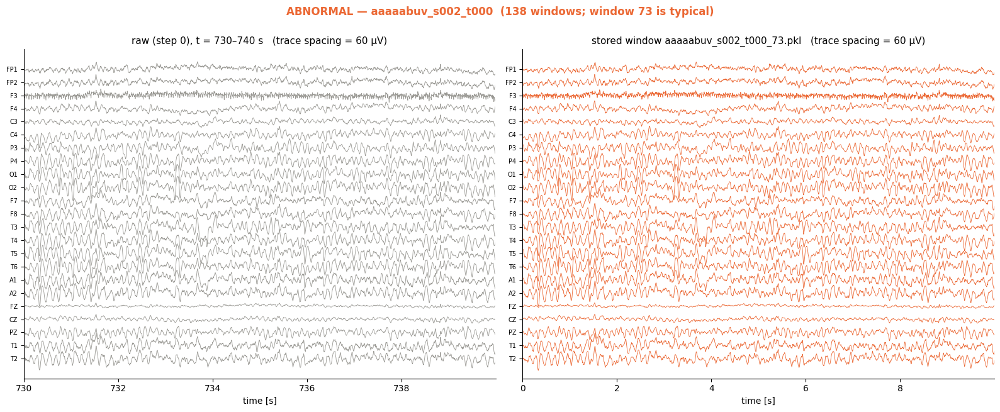

In [19]:
N_GALLERY = 3
gallery = [(0, s) for s in eval_normal[:N_GALLERY]] + [(1, s) for s in eval_abnormal[:N_GALLERY]]

def typical_window(windows):
    p99 = np.percentile(np.abs(windows), 99, axis=(1, 2))
    return int(np.argsort(p99)[len(p99) // 2])

for label, stem in gallery:
    try:
        stages, windows = run_pipeline(edf_path("eval", label, stem), keep_stages=False)
    except RuntimeError as e:
        print("skipped:", e)
        continue
    k = typical_window(windows)
    Xr, chr_, sfr = stages["0 raw"]
    eeg = [chr_.index(c) for c in chOrder_standard]
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
    sp = plot_stacked(axes[0], Xr[eeg], chOrder_standard, sfr, k * 10, 10, color=C_BEFORE,
                      title=f"raw (step 0), t = {k * 10}–{k * 10 + 10} s")
    plot_stacked(axes[1], windows[k], chOrder_standard, TARGET_SFREQ, 0, 10, spacing=sp,
                 color=CLASS_COLOR[label], title=f"stored window {stem}_{k}.pkl")
    fig.suptitle(f"{CLASS_NAME[label].upper()} — {stem}  ({len(windows)} windows; window {k} is typical)",
                 y=1.0, color=CLASS_COLOR[label], fontweight="bold")
    plt.tight_layout()
    plt.show()

### Class-level comparison (many recordings)

A single window says little; averaging over many recordings shows the systematic difference.
We take `N_PER_CLASS` test recordings per class from `processed/test` (the stored pickles,
i.e. exactly what the model sees), up to 12 evenly spaced windows each, and compute

* the Welch PSD of each window (2 s Hann segments, 0.5 Hz resolution), averaged over the 23
  channels and then over the windows of a recording; we plot the class **median and
  inter-quartile range across recordings**;
* the **relative band power** per recording,

$$
P^{\text{rel}}_{b} = \frac{\int_{f \in b} S(f)\,df}{\int_{0.5}^{45} S(f)\,df},\qquad
b \in \{\delta: 0.5\text{–}4,\ \theta: 4\text{–}8,\ \alpha: 8\text{–}13,\ \beta: 13\text{–}30,\ \gamma: 30\text{–}45\}\ \text{Hz}
$$

(the denominator stops at 45 Hz so that the untouched 60 Hz mains line does not distort the ratios).

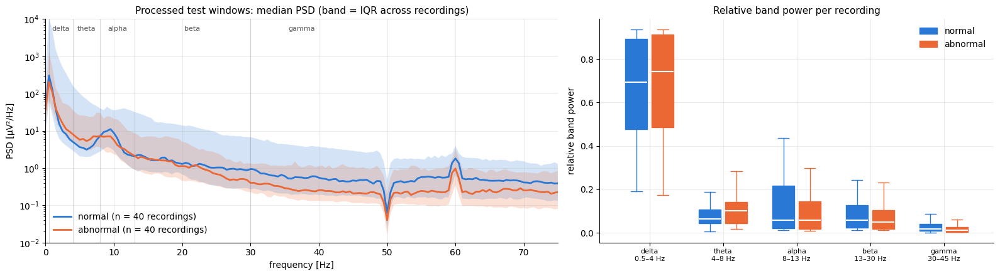

band     normal median  abnormal median
delta            0.692            0.743
theta            0.063            0.101
alpha            0.060            0.059
beta             0.058            0.051
gamma            0.019            0.013

99th-percentile |amplitude| per recording (µV): normal median 141, abnormal median 79


In [20]:
N_PER_CLASS, MAX_WIN = 40, 12
BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 45)}

def class_stats():
    test_dir = PROCESSED / "test"
    by_stem = collections.defaultdict(list)
    for fn in os.listdir(test_dir):
        stem, k = fn[:-4].rsplit("_", 1)
        by_stem[stem].append(int(k))
    wanted = {0: [s for s in eval_normal if s in by_stem][:N_PER_CLASS],
              1: [s for s in eval_abnormal if s in by_stem][:N_PER_CLASS]}
    out = {}
    for label, stems in wanted.items():
        psds, bandp, amp = [], [], []
        for stem in stems:
            ks = sorted(by_stem[stem])
            pick = np.unique(np.linspace(0, len(ks) - 1, min(MAX_WIN, len(ks))).round().astype(int))
            Ws = []
            for j in pick:
                with open(test_dir / f"{stem}_{ks[j]}.pkl", "rb") as fh:
                    s = pickle.load(fh)
                assert int(s["y"]) == label
                Ws.append(s["X"])
            Ws = np.stack(Ws)                                    # [k, 23, 2000]
            f, P = ss.welch(Ws, fs=TARGET_SFREQ, nperseg=400, axis=-1)
            P = P.mean(axis=(0, 1))                              # mean over windows & channels
            psds.append(P)
            tot = np.trapz(P[(f >= 0.5) & (f <= 45)], f[(f >= 0.5) & (f <= 45)])
            bandp.append([np.trapz(P[(f >= lo) & (f <= hi)], f[(f >= lo) & (f <= hi)]) / tot
                          for lo, hi in BANDS.values()])
            amp.append(np.percentile(np.abs(Ws), 99))
        out[label] = dict(f=f, psd=np.array(psds), band=np.array(bandp), amp=np.array(amp), stems=stems)
    return out

if (PROCESSED / "test").exists():
    stats = class_stats()
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
    ax = axes[0]
    for label in (0, 1):
        f, P = stats[label]["f"], np.log10(stats[label]["psd"])
        q25, q50, q75 = np.percentile(P, [25, 50, 75], axis=0)
        ax.fill_between(f, 10 ** q25, 10 ** q75, color=CLASS_COLOR[label], alpha=0.2, lw=0)
        ax.semilogy(f, 10 ** q50, color=CLASS_COLOR[label], lw=2,
                    label=f"{CLASS_NAME[label]} (n = {len(P)} recordings)")
    for lo, hi in BANDS.values():
        ax.axvline(lo, color="0.85", lw=0.8, zorder=0)
    for name, (lo, hi) in BANDS.items():
        ax.text((lo + hi) / 2, 0.97, name, ha="center", va="top", fontsize=8, color="0.35",
                transform=ax.get_xaxis_transform())
    ax.set_xlim(0, 75)
    ax.set_ylim(1e-2, 1e4)
    ax.set_xlabel("frequency [Hz]")
    ax.set_ylabel("PSD [µV²/Hz]")
    ax.set_title("Processed test windows: median PSD (band = IQR across recordings)")
    ax.legend(loc="lower left")

    ax = axes[1]
    names = list(BANDS)
    pos = np.arange(len(names))
    for j, label in enumerate((0, 1)):
        bp = ax.boxplot(stats[label]["band"], positions=pos + (j - 0.5) * 0.36, widths=0.3,
                        patch_artist=True, showfliers=False, medianprops=dict(color="white", lw=1.5))
        for b in bp["boxes"]:
            b.set(facecolor=CLASS_COLOR[label], edgecolor=CLASS_COLOR[label])
        for part in ("whiskers", "caps"):
            for l_ in bp[part]:
                l_.set(color=CLASS_COLOR[label])
    ax.set_xticks(pos, [f"{n}\n{lo}–{hi} Hz" for n, (lo, hi) in BANDS.items()], fontsize=8)
    ax.set_ylabel("relative band power")
    ax.set_title("Relative band power per recording")
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=CLASS_COLOR[l]) for l in (0, 1)],
              [CLASS_NAME[l] for l in (0, 1)])
    plt.tight_layout()
    plt.show()

    print(f"{'band':7s} {'normal median':>14s} {'abnormal median':>16s}")
    for j, n in enumerate(names):
        print(f"{n:7s} {np.median(stats[0]['band'][:, j]):14.3f} {np.median(stats[1]['band'][:, j]):16.3f}")
    print("\n99th-percentile |amplitude| per recording (µV): "
          f"normal median {np.median(stats[0]['amp']):.0f}, abnormal median {np.median(stats[1]['amp']):.0f}")
else:
    print("processed/test not found — skipping class-level statistics")

**Reading the result** (for the saved run: the first 40 test recordings of each class).
The normal median spectrum has a distinct **alpha peak around 10 Hz**, which is flattened in the
abnormal group, and abnormal recordings carry a larger **relative delta and theta** share
(slowing). The groups overlap heavily, though — the IQR bands and boxes intersect in every band —
which is why the task needs a learned model rather than a single spectral threshold. Both groups
show the notch dip at 50 Hz and the untouched mains peak at 60 Hz.

### Spectrogram of whole recordings

The time-frequency picture over the full recording (after preprocessing, O1 — an occipital
channel where the alpha rhythm is strongest). Horizontal bands = sustained rhythms
(alpha ~10 Hz, the faint 60 Hz mains line, the dark 50 Hz notch), vertical stripes = broadband artefacts (movement, electrode
pops) that are kept in the training data.

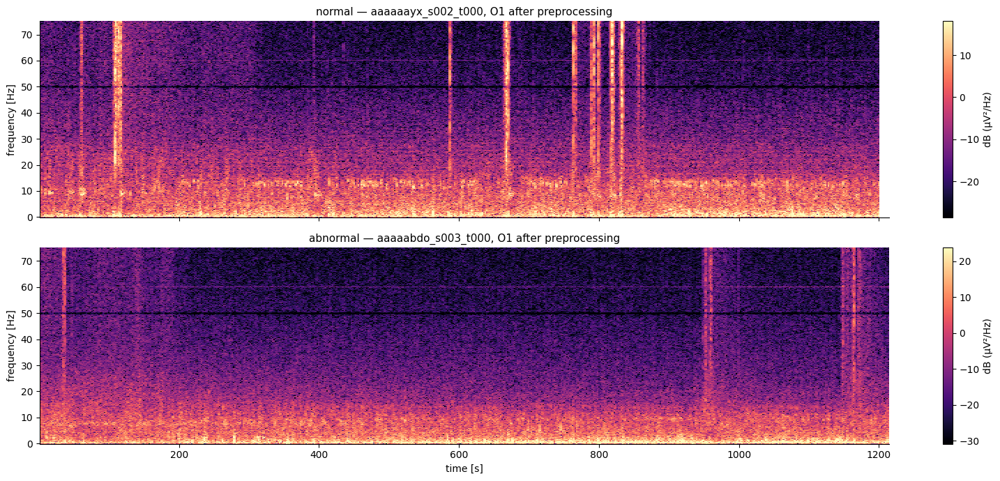

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
for ax, (label, stem) in zip(axes, examples.items()):
    X, ch, sf = pipe[label][0]["4 resampled"]
    i = ch.index("EEG O1-REF")
    f, t, S = ss.spectrogram(X[i], fs=sf, nperseg=int(4 * sf), noverlap=int(2 * sf))
    m = f <= 75
    pc = ax.pcolormesh(t, f[m], 10 * np.log10(S[m] + 1e-6), shading="auto", cmap="magma",
                       vmin=np.percentile(10 * np.log10(S[m] + 1e-6), 5),
                       vmax=np.percentile(10 * np.log10(S[m] + 1e-6), 99.5))
    ax.set_ylabel("frequency [Hz]")
    ax.set_title(f"{CLASS_NAME[label]} — {stem}, O1 after preprocessing")
    ax.grid(False)
    plt.colorbar(pc, ax=ax, label="dB (µV²/Hz)")
axes[-1].set_xlabel("time [s]")
plt.tight_layout()
plt.show()

## 11. Summary of formulas & caveats

| Step | Operation | Formula | Parameters (MNE defaults in *italics*) |
|------|-----------|---------|----------------------------------------|
| 0 | EDF → µV | $x = 10^{6}\,[p_{\min} + (d - d_{\min})\frac{p_{\max}-p_{\min}}{d_{\max}-d_{\min}}]$ | $f_s = 250$ Hz |
| 1 | channel selection | $\mathcal C = \mathcal C_{\text{raw}}\setminus\mathcal D$, reorder by $\pi$, require 23 | `drop_channels`, `chOrder_standard` |
| 2 | band-pass | $y = h * x$ (zero phase), $h = w_{\text{Hamming}}\cdot(h_{\text{LP},f_2} - h_{\text{LP},f_1})$ | 0.1–75 Hz, *firwin, 8251 taps, Δf = 0.1 / 18.75 Hz* |
| 3 | notch | $h = \delta - h_{\text{BP}}^{[50\pm0.125]}$ | 50 Hz, *width 0.25 Hz, transition 1 Hz* |
| 4 | resample | $x' = \frac{N'}{N}\,\text{IDFT}_{N'}\{X[k]\}_{\lvert k\rvert<N'/2}$ | 250 → 200 Hz, *FFT, boxcar* |
| 5 | windowing | $X_k = X[:, 2000k:2000(k+1)]$, $K = \lfloor N'/2000\rfloor$, $y_k = y$ | 10 s, no overlap, tail dropped |
| 6 | model input | $\tilde x_{c,a,t} = X_{c,200a+t}/100$ | `[23, 10, 200]` |
| 7 | *(LaBraM++)* | CAR $x - \bar x_{\text{channels}}$, then $(x-\mu)/(\sigma+\varepsilon)$ per patch | opt-in |

**Caveats worth knowing**

1. **60 Hz mains noise is not removed** (section 5): the notch is at 50 Hz but TUH is US data.
2. **No artefact handling**: no rejection of bad windows/channels, no re-referencing (unless
   LaBraM++), only a fixed ÷100 scale. High-amplitude artefact windows go into training as-is.
3. **Weak labels**: each 10 s window inherits the recording-level label; an abnormal
   recording can contain many normal-looking windows. Recording-level evaluation (aggregating
   window predictions, see `docs/finetune_evaluation.md`) is closer to the clinical question.
4. **Split reproducibility / leakage**: `make_TUAB.py` calls `np.random.shuffle` **without a
   seed**, and splits normal and abnormal subjects **independently**, so a subject who has both
   normal and abnormal recordings can land in train for one and val for the other (checked below).
   The official `eval/` test set is fixed and unaffected. `docs/age_regression.md` describes a
   seeded, subject-disjoint split.
5. **Skipped recordings**: files whose channel set does not reduce to exactly the 23 channels are
   dropped (logged to `tuab-process-error-files.txt`) — checked below.

In [22]:
if PROCESSED.exists():
    proc_stems, proc_subj = {}, {}
    for split in ("train", "val", "test"):
        stems = {fn[:-4].rsplit("_", 1)[0] for fn in os.listdir(PROCESSED / split)}
        proc_stems[split] = stems
        proc_subj[split] = {s.split("_")[0] for s in stems}
        print(f"processed/{split:5s}: {len(stems):5d} recordings, {len(proc_subj[split]):5d} subjects")

    edf_stems = {p.stem for sp in ("train", "eval") for c in ("normal", "abnormal")
                 for p in (TUAB_ROOT / sp / c / MONTAGE).glob("*.edf")}
    all_proc = set().union(*proc_stems.values())
    print(f"\nEDF recordings: {len(edf_stems)}, processed: {len(all_proc)}, "
          f"skipped by make_TUAB.py: {sorted(edf_stems - all_proc)}")

    leak = proc_subj["train"] & proc_subj["val"]
    both = ({p.stem.split('_')[0] for p in (TUAB_ROOT / 'train/normal' / MONTAGE).glob('*.edf')}
            & {p.stem.split('_')[0] for p in (TUAB_ROOT / 'train/abnormal' / MONTAGE).glob('*.edf')})
    print(f"subjects with both normal and abnormal recordings in train/: {len(both)}")
    print(f"subjects present in BOTH processed/train and processed/val (leakage): {len(leak)}")
    print(f"subjects shared between train/val and test: {len((proc_subj['train'] | proc_subj['val']) & proc_subj['test'])}")
else:
    print("processed/ folder not found — skipping")

processed/train:  2142 recordings,  1668 subjects
processed/val  :   572 recordings,   423 subjects
processed/test :   276 recordings,   253 subjects

EDF recordings: 2993, processed: 2990, skipped by make_TUAB.py: ['aaaaajsl_s010_t000', 'aaaaakfo_s004_t000', 'aaaaakfo_s005_t000']
subjects with both normal and abnormal recordings in train/: 54
subjects present in BOTH processed/train and processed/val (leakage): 16
subjects shared between train/val and test: 0


## 12. How do other state-of-the-art models prepare EEG?

LaBraM's recipe is one choice among many. The tables below compare the published
preprocessing of (a) **EEG foundation models** and (b) **EEG age-prediction ("brain age")
models**, the downstream task this repo also supports (`data.dataset=TUAB_AGE`,
`docs/age_regression.md`). The values were taken from each paper's methods/appendix and, where
marked *(code)*, from the official preprocessing scripts. "n/s" = not stated in the paper.

### 12a. EEG foundation models

| Model (venue) | Pre-training data | Channels / reference | Band-pass · notch | Rate | Amplitude scaling | Artefact handling | Window · token | Input representation |
|---|---|---|---|---|---|---|---|---|
| **BENDR** (Kostas et al., *Front. Hum. Neurosci.* 2021) | TUEG v1.1–1.2, ~1.5 TB, >10k people | 19 ch (10-20, DN3 mapping), missing → 0, **+1 relative-amplitude channel**; no re-ref | none (only Nyquist-safe files kept) | 256 Hz | each sequence min–max scaled to **[−1, 1]** | none | 60 s · conv tokens ≈ 0.375 s (96× down-sampling) | raw time series |
| **BIOT** (Yang et al., *NeurIPS* 2023) | SHHS + PREST (private), ~10 M samples; some variants on TUAB/IIIC/CHB-MIT | **16 bipolar TCP** (double banana) computed from `-REF` chans *(code)*; missing channels → dropped tokens | **none** *(code)* | 200 Hz | per channel ÷ **95th percentile of \|x\|** per sample *(code)* | none | TUAB 10 s · 1 s tokens, 0.5 s overlap | **STFT** energy per token (n_fft = 200, hop 100) |
| **LaBraM** (Jiang et al., *ICLR* 2024) — *this repo* | ~2,535 h, ~20 datasets (TUSZ, TUEP, SEED, …) | up to 128 ch, learned 10-20 spatial embedding; TUAB **23 referential** `-REF` chans; no re-ref | **0.1–75 Hz · 50 Hz** | 200 Hz | µV **÷ 100** (0.1 mV units) | none | TUAB 10 s · 1 s patches (200 samples), ≤ 256 patches | raw patches (VQ tokenizer target: Fourier amplitude & phase) |
| **EEGPT** (Wang et al., *NeurIPS* 2024) | PhysioMI, HGD, TSU, SEED, M3CV | 58 ch, **average reference** in pre-training; downstream 1×1-conv "adaptive spatial filter" | n/s for pre-training (0–38 Hz for MI downstream) | 256 Hz | **mV** (V × 1000) | n/s | 4 s · 250 ms patches (64 samples) | raw patches |
| **CBraMod** (Wang et al., *ICLR* 2025) | TUEG, >9,000 h after cleaning | 19 ch referential (`-REF`/`-LE`); conv positional encoding; TUAB **16 bipolar TCP** *(code)* | **0.3–75 Hz · 60 Hz** | 200 Hz | µV **÷ 100** | drop recordings ≤ 5 min, **drop first & last minute**, **reject 30 s samples with \|x\| > 100 µV** | 30 s (TUAB 10 s) · 1 s patches | raw patch (time-conv) + FFT branch |
| **NeuroLM** (Jiang et al., *ICLR* 2025) | ~25,000 h (~24,000 h TUEG) | variable, LaBraM-style spatial embedding; TUAB 23 ch | 0.1–75 Hz · **50 or 60 Hz by region** | 200 Hz | µV **÷ 100** | n/s | TUAB 10 s · 1 s patches, ≤ 1,024 patches | VQ tokens → GPT-2 (multi-task LLM) |
| **Neuro-GPT** (Cui et al., *ISBI* 2024) | TUH EEG, 20k recordings, 5,656 h | 22 ch, bad chans interpolated, **average reference** | **0.5–100 Hz · 60 Hz** | 250 Hz | DC removal, detrend, **z-score per recording** | bad-channel interpolation | 32 × 2 s chunks (10 % overlap) | raw chunks → conv + transformer → GPT-2 |
| **FEMBA** (Tegon et al., arXiv 2025) | TUEG ~21,000 h (TUAB/TUAR/TUSL removed) | n/s | n/s | n/s | per channel **IQR (quartile) scaling** | n/s | 2-D patches (4 ch × 32 samples) | raw patches → bidirectional Mamba |
| **REVE** (El Ouahidi et al., *NeurIPS* 2025) | 61,415 h, 92 datasets, ~25k subjects | any montage, **4-D (xyz + time) positional encoding** | **0.5–99.5 Hz** · n/s | 200 Hz | **z-score** (session stats), **clip ±15 SD** | none (no rejection) | ~10 s · 1 s patches (0.1 s overlap) | raw patches |

Footnotes: BENDR/BIOT/EEGPT do not report pre-training hours. EEGPT's paper text says 256 Hz for TUAB, but its
released TUAB script is LaBraM's pipeline (0.1–75 Hz, 50 Hz notch, 200 Hz, ÷100). FEMBA's filter/rate/montage are
not given in the paper.

### 12b. EEG age-prediction (brain-age) models

| Work | Data (N, age) | Channels / reference | Filtering | Rate | Artefact handling | Segments | Scaling | Features → model | Recording-level age | MAE |
|---|---|---|---|---|---|---|---|---|---|---|
| **Engemann et al.**, *NeuroImage* 2022 — M/EEG brain-age benchmark *(values from code)* | TUAB **normal** recordings, 1,385 subj., 0–95 y (+ Cam-CAN, LEMON, CHBP) | 21 ch (10-20 + A1/A2), **average reference** | **0.1–49 Hz**, no notch | 200 Hz | **autoreject** on epochs | 10 s | µV ÷ 9.7 (dataset SD) for deep nets | filter-bank **Riemann** covariances (7 bands) + ridge; hand-crafted + RF; ShallowNet / Deep4 | mean of window predictions | TUAB: Deep4 7.75, Shallow 7.80, Riemann 8.25 y |
| **Gemein et al.**, *Imaging Neurosci.* 2024 — "Brain age revisited" | TUAB, 2,647 rec. / 2,159 subj. (train on non-pathological) | 21 ch, **common average** | n/s | **100 Hz** | **drop first minute**, **clip ±800 µV** | braindecode cropped decoding (stride 1) | channel z-score (train stats); target min-max [0, 1] | BD-TCN, L1 loss | crop mean (likely; not explicit) | 6.6 y (R² 0.73) |
| *Gemein et al.*, *NeuroImage* 2020 — TUAB **pathology** (the reference braindecode TUAB recipe) | TUAB 2,993 rec. | 21 ch | none | 100 Hz | drop first 60 s, ≤ 20 min, clip ±800 µV | ~6 s receptive-field crops | — | Deep4 / Shallow / TCN / EEGNet; RF / SVM / Riemann | crop aggregation | (classification, 86 % acc.) |
| **Sun et al.**, *Neurobiol. Aging* 2019 — sleep EEG | MGH PSG, 2,532 (18–80 y) | 6 ch (F3/F4/C3/C4/O1/O2 – contralateral mastoid) | **0.5–20 Hz · 60 Hz** | 200 Hz | reject 30 s epochs > 500 µV, flat > 2 s, ECG-contaminated | 30 s sleep epochs | per channel median / IQR over the night | 102 features × 5 sleep stages → regularised linear model | features averaged per stage | 7.8 y |
| **Brink-Kjaer et al.**, *npj Digit. Med.* 2022 — deep PSG | 13,332 PSGs, 7 cohorts, 6–90 y | C3-M2, C4-M1 (+ EOG/EMG/ECG variants) | 0.3–45 Hz elliptic IIR, zero phase | 128 Hz | n/s | 5 min epochs | 5th/95th percentile → [−1, 1] | CNN + Bi-LSTM + attention, Huber loss | 2nd-stage Bi-LSTM + attention over the night | 5.8 y |
| **Khayretdinova et al.**, *Front. Aging Neurosci.* 2022 | TD-BRAIN, 1,335 sessions, 5–88 y | 26 ch (10-10), averaged mastoids | **0.5–100 Hz · 50/60 Hz** | 500 Hz | EOG regression + automatic EMG / jump / kurtosis / blink detection, flagged segments dropped | 5 s, 1 s step | n/s | deep CNN with channel-permutation stacking, L1 loss | mean of clean-segment predictions | 5.96 y |
| **Sabbagh et al.**, *BJA Open* 2023 — anaesthesia EEG | 323 patients ≥ 18 y | 4 frontal (Fp1/Fp2/F7/F8 – Cz) | n/s | 63 Hz | burst-suppression / artefacts removed by vendor export; keep stable-anaesthesia segment | 60 s, 10 s shift | — | PSD + 5-band covariances (coffeine) → ridge | averaged over epochs | ~8.2 y |
| **Banville et al.**, *Imaging Neurosci.* 2024 — Muse mobile EEG | 4,191 meditation + 1,020 sleep rec., 18–81 y | 4 ch (TP9, Fp1, Fp2, TP10), Fpz ref | 0.1–49 Hz FIR + notches 16 … 60 Hz | 128 Hz | crop first minute; reject windows with peak-to-peak > 250 µV | 10 s / 30 s | — | filter-bank covariances → ridge | averaged features | 9.3 y / 7.6 y |
| **This repo**, `TUAB_AGE` (`docs/age_regression.md`) | TUAB, age from EDF header, subject-disjoint split | 23 ch referential (LaBraM) | 0.1–75 Hz · 50 Hz | 200 Hz | none | 10 s | µV ÷ 100; **target** z-scored with train stats | fine-tuned LaBraM, Huber loss | mean / median / max of windows | — (literature range 7–8 y) |

### 12c. What differs, and why it matters

* **Montage.** On TUAB, BIOT and CBraMod use the **16-channel bipolar TCP** montage; LaBraM, NeuroLM and
  EEGPT use **23 referential** channels; the brain-age works use **21 channels re-referenced to the
  common average**. Bipolar and average-reference montages remove the signal shared by all
  electrodes in each derivation, e.g. the activity of the shared reference electrode; with referential
  channels (LaBraM) that shared component stays in every channel.
* **Line noise.** TUH is US data (60 Hz). LaBraM/EEGPT notch at 50 Hz (section 5), CBraMod and
  Neuro-GPT at 60 Hz, NeuroLM by region; the TUAB age benchmarks avoid the issue with a ≤ 49 Hz low-pass or a
  100 Hz rate (Nyquist 50 Hz).
* **Amplitude scaling** falls into three families: a **fixed physical unit** (÷100 µV: LaBraM, CBraMod,
  NeuroLM; mV: EEGPT; ÷9.7 µV: Engemann) keeps absolute amplitude, which carries information
  (amplitude falls with age); **per-sample/per-channel normalisation** (BIOT 95th percentile, FEMBA
  IQR, BENDR min-max) discards it; **z-scoring with dataset/session statistics** (Gemein, REVE,
  Neuro-GPT) is in between.
* **Artefacts.** The foundation models mostly keep everything (CBraMod is the exception, rejecting
  windows with |x| > 100 µV and the first/last minute), whereas the brain-age literature almost always
  removes or clips artefacts (autoreject, ±800 µV clip, peak-to-peak thresholds, first-minute crop).
* **Recording-level aggregation.** Every brain-age work predicts **one age per recording**, typically by
  averaging window predictions or features, which is why this repo evaluates age per recording.

The cells below re-implement five of these recipes (simplified, see notes) and apply them to the **same
abnormal recording and the same 10 s excerpt** used above, so the differences become visible.

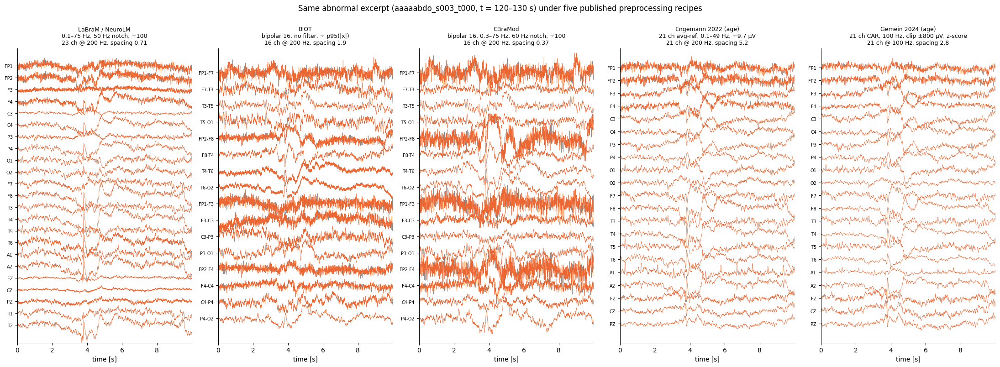

In [23]:
# Simplified re-implementations of published recipes, applied to step-1 data
# (23 referential channels, 250 Hz, µV, unfiltered). Simplifications:
#  * Engemann 2022: autoreject is skipped.
#  * Gemein 2024: z-score uses this recording's statistics instead of the training-set statistics.
#  * BIOT / CBraMod: TUAB bipolar TCP montage computed from the referential channels, as their scripts do.
TCP_PAIRS = [("FP1", "F7"), ("F7", "T3"), ("T3", "T5"), ("T5", "O1"),
             ("FP2", "F8"), ("F8", "T4"), ("T4", "T6"), ("T6", "O2"),
             ("FP1", "F3"), ("F3", "C3"), ("C3", "P3"), ("P3", "O1"),
             ("FP2", "F4"), ("F4", "C4"), ("C4", "P4"), ("P4", "O2")]
CH21 = [c for c in chOrder_standard if short(c) not in ("T1", "T2")]


def bipolar(X, ch):
    idx = {short(c): i for i, c in enumerate(ch)}
    return np.stack([X[idx[a]] - X[idx[b]] for a, b in TCP_PAIRS]), [f"{a}-{b}" for a, b in TCP_PAIRS]


def recipes(X1, ch, sf):
    # X1: [23, N] µV at sf (step-1 output). Returns name -> (X, channel labels, rate, unit).
    out = {}
    # LaBraM (this repo): 0.1-75 Hz, 50 Hz notch, 200 Hz, ÷100
    x = mne.filter.filter_data(X1, sf, 0.1, 75.0)
    x = mne.filter.notch_filter(x, sf, 50.0)
    out["LaBraM / NeuroLM\n0.1–75 Hz, 50 Hz notch, ÷100"] = (
        mne.filter.resample(x, TARGET_SFREQ / sf) / 100, ch, 200, "×100 µV")
    # BIOT: bipolar 16, resample 200 Hz, no filter, per-channel ÷ 95th pct of |x| (per window, below)
    xb, chb = bipolar(X1, ch)
    out["BIOT\nbipolar 16, no filter, ÷ p95(|x|)"] = (mne.filter.resample(xb, TARGET_SFREQ / sf), chb, 200, "p95")
    # CBraMod (TUAB): bipolar 16, resample 200, 0.3-75 Hz, 60 Hz notch, ÷100
    x = mne.filter.resample(xb, TARGET_SFREQ / sf)
    x = mne.filter.filter_data(x, 200., 0.3, 75.0)
    x = mne.filter.notch_filter(x, 200., 60.0)
    out["CBraMod\nbipolar 16, 0.3–75 Hz, 60 Hz notch, ÷100"] = (x / 100, chb, 200, "×100 µV")
    # Engemann 2022: 21 ch, 0.1-49 Hz, 200 Hz, average reference, ÷9.7 µV
    i21 = [ch.index(c) for c in CH21]
    x = mne.filter.filter_data(X1[i21], sf, 0.1, 49.0)
    x = mne.filter.resample(x, TARGET_SFREQ / sf)
    x = x - x.mean(axis=0, keepdims=True)
    out["Engemann 2022 (age)\n21 ch avg-ref, 0.1–49 Hz, ÷9.7 µV"] = (x / 9.7, CH21, 200, "×9.7 µV")
    # Gemein 2024: 21 ch, 100 Hz, drop first minute, clip ±800 µV, common average, channel z-score
    x = mne.filter.resample(X1[i21], 100.0 / sf)
    x = np.clip(x, -800, 800)
    x = x - x.mean(axis=0, keepdims=True)
    x[:, :60 * 100] = np.nan                                     # first minute discarded
    mu, sd = np.nanmean(x, axis=1, keepdims=True), np.nanstd(x, axis=1, keepdims=True)
    out["Gemein 2024 (age)\n21 ch CAR, 100 Hz, clip ±800 µV, z-score"] = ((x - mu) / sd, CH21, 100, "σ")
    return out


X1, ch1, sf1 = pipe[1][0]["1 channels"]
alt = recipes(X1, ch1, sf1)

fig, axes = plt.subplots(1, len(alt), figsize=(22, 8), sharex=True)
for ax, (name, (X, chs, sf, unit)) in zip(axes, alt.items()):
    i0, i1 = int(SHOW_T0 * sf), int((SHOW_T0 + SHOW_DUR) * sf)
    W = X[:, i0:i1]
    if unit == "p95":                                             # BIOT normalises each sample (window)
        W = W / (np.quantile(np.abs(W), 0.95, axis=-1, keepdims=True) + 1e-8)
    sp = 4.0 * np.median(np.std(W - W.mean(1, keepdims=True), axis=1))
    plot_stacked(ax, W, chs, sf, 0, SHOW_DUR, spacing=float(f"{sp:.2g}"), color=C_ABNORMAL, lw=0.5,
                 labels=[short(c) if c.startswith("EEG") else c for c in chs])
    ax.set_title(name + f"\n{len(chs)} ch @ {sf} Hz, spacing {sp:.2g}", fontsize=9)
fig.suptitle(f"Same abnormal excerpt ({EXAMPLE_ABNORMAL}, t = {SHOW_T0:.0f}–{SHOW_T0 + SHOW_DUR:.0f} s) "
             "under five published preprocessing recipes", y=1.0)
plt.tight_layout()
plt.show()

**Which frequencies does each recipe pass to the model?** Spectra of the whole recording under
each recipe, each normalised to its own total power so that the differing units do not matter.
Look at the upper cut-off (49 / 50 / 75 / 100 Hz) and the notch position (50 vs 60 Hz): on this
recording only CBraMod's 60 Hz notch, Engemann's 49 Hz low-pass and Gemein's 100 Hz rate keep the
mains line out of the model input. The re-montaging alone (bipolar in BIOT) does not remove it.

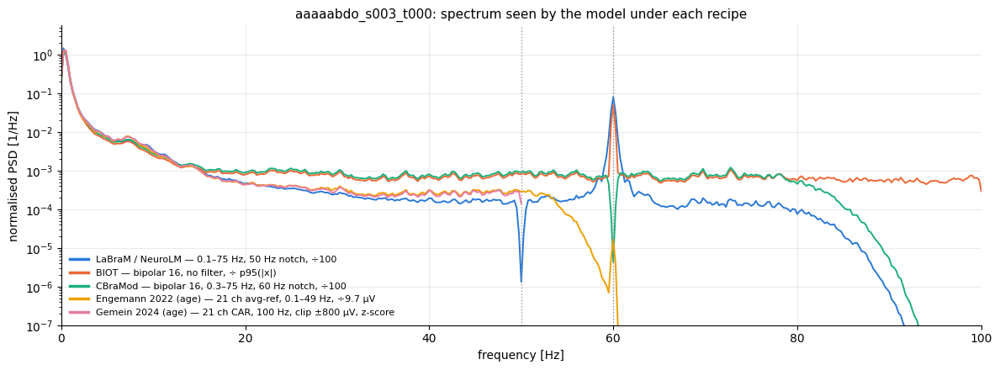

recipe                                                       60 Hz power vs 1–45 Hz EEG power


LaBraM / NeuroLM — 0.1–75 Hz, 50 Hz notch, ÷100                                       -6.2 dB
BIOT — bipolar 16, no filter, ÷ p95(|x|)                                              -9.4 dB


CBraMod — bipolar 16, 0.3–75 Hz, 60 Hz notch, ÷100                                   -31.5 dB


Engemann 2022 (age) — 21 ch avg-ref, 0.1–49 Hz, ÷9.7 µV                              -44.2 dB
Gemein 2024 (age) — 21 ch CAR, 100 Hz, clip ±800 µV, z-score               none (Nyquist 50 Hz)


In [24]:
fig, ax = plt.subplots(figsize=(12, 4.5))
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # fixed categorical order
for col, (name, (X, chs, sf, unit)) in zip(palette, alt.items()):
    Xv = X[:, ~np.isnan(X).any(axis=0)]
    f, P = welch_psd(Xv, sf, seg_sec=4.0)
    Pm = P.mean(0)
    ax.semilogy(f, Pm / np.trapz(Pm, f), color=col, lw=1.4, label=name.replace("\n", " — "))
for f0 in (50, 60):
    ax.axvline(f0, color="0.6", ls=":", lw=1)
ax.set_xlim(0, 100)
ax.set_ylim(1e-7, None)
ax.set_xlabel("frequency [Hz]")
ax.set_ylabel("normalised PSD [1/Hz]")
ax.set_title(f"{EXAMPLE_ABNORMAL}: spectrum seen by the model under each recipe")
thick_legend(ax, fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

# Line-noise power that reaches the model: power in 59.5-60.5 Hz relative to the 1-45 Hz EEG band (dB)
print(f"{'recipe':58s} {'60 Hz power vs 1–45 Hz EEG power':>34s}")
for name, (X, chs, sf, unit) in alt.items():
    Xv = X[:, ~np.isnan(X).any(axis=0)]
    if sf / 2 <= 60.5:
        print(f"{name.replace(chr(10), ' — '):58s} {'none (Nyquist ' + str(sf // 2) + ' Hz)':>34s}")
        continue
    f, P = welch_psd(Xv, sf, seg_sec=8.0)
    Pm = P.mean(0)
    line = np.trapz(Pm[(f >= 59.5) & (f <= 60.5)], f[(f >= 59.5) & (f <= 60.5)])
    eeg = np.trapz(Pm[(f >= 1) & (f <= 45)], f[(f >= 1) & (f <= 45)])
    print(f"{name.replace(chr(10), ' — '):58s} {10 * np.log10(line / eeg):31.1f} dB")

**References** (preprocessing values verified against the papers' methods sections and, where noted, official code)

* Kostas, Aroca-Ouellette & Rudzicz (2021). *BENDR.* Front. Hum. Neurosci. — [arXiv:2101.12037](https://arxiv.org/abs/2101.12037)
* Yang, Westover & Sun (2023). *BIOT.* NeurIPS — [arXiv:2305.10351](https://arxiv.org/abs/2305.10351), code: github.com/ycq091044/BIOT
* Jiang, Zhao & Lu (2024). *LaBraM.* ICLR — [arXiv:2405.18765](https://arxiv.org/abs/2405.18765), code: github.com/935963004/LaBraM
* Wang et al. (2024). *EEGPT.* NeurIPS — [paper](https://papers.neurips.cc/paper_files/paper/2024/file/4540d267eeec4e5dbd9dae9448f0b739-Paper-Conference.pdf), code: github.com/BINE022/EEGPT
* Wang et al. (2025). *CBraMod.* ICLR — [arXiv:2412.07236](https://arxiv.org/abs/2412.07236), code: github.com/wjq-learning/CBraMod
* Jiang et al. (2025). *NeuroLM.* ICLR — [arXiv:2409.00101](https://arxiv.org/abs/2409.00101)
* Cui et al. (2024). *Neuro-GPT.* ISBI — [arXiv:2311.03764](https://arxiv.org/abs/2311.03764)
* Tegon et al. (2025). *FEMBA.* — [arXiv:2502.06438](https://arxiv.org/abs/2502.06438)
* El Ouahidi et al. (2025). *REVE.* NeurIPS — [arXiv:2510.21585](https://arxiv.org/abs/2510.21585)
* Engemann et al. (2022). *A reusable benchmark of brain-age prediction from M/EEG resting-state signals.* NeuroImage 262:119521 — [doi](https://doi.org/10.1016/j.neuroimage.2022.119521), code: github.com/meeg-ml-benchmarks/brain-age-benchmark-paper
* Gemein et al. (2024). *Brain age revisited.* Imaging Neuroscience — [doi:10.1162/imag_a_00210](https://doi.org/10.1162/imag_a_00210)
* Gemein et al. (2020). *Machine-learning-based diagnostics of EEG pathology.* NeuroImage 220:117021 — [arXiv:2002.05115](https://arxiv.org/abs/2002.05115)
* Sun et al. (2019). *Brain age from the electroencephalogram of sleep.* Neurobiol. Aging 74:112–120 — [doi](https://doi.org/10.1016/j.neurobiolaging.2018.10.016)
* Brink-Kjaer et al. (2022). *Age estimation from sleep studies using deep learning.* npj Digit. Med. 5:103 — [doi](https://doi.org/10.1038/s41746-022-00630-9)
* Khayretdinova et al. (2022). *Predicting age from resting-state scalp EEG with deep CNNs on TD-BRAIN.* Front. Aging Neurosci. 14:1019869 — [doi](https://doi.org/10.3389/fnagi.2022.1019869)
* Sabbagh et al. (2023). *Repurposing EEG monitoring of general anaesthesia for brain-age prediction.* BJA Open — [doi](https://doi.org/10.1016/j.bjao.2023.100145)
* Banville et al. (2024). *Brain age from mobile (Muse) EEG.* Imaging Neuroscience — [doi](https://doi.org/10.1162/imag_a_00189)

---
**Where to go next**
* `dataset_maker/make_TUAB.py` — the offline script (run it once to create `processed/`).
* `labram/data/tuh_datasets.py` — `TUABLoader` / `prepare_TUAB_dataset` (reads the pickles).
* `labram/train/train_finetune.py` — ÷100 scaling and patching.
* `docs/labram_plus_plus.md` — CAR + z-score + sin/cos phase loss.
* `notebooks/finetune_evaluation.ipynb` — evaluating a fine-tuned model per window and per recording.